In [16]:
# ═══════════════════════════════════════════════════════════════════
# STEP 6: Diagnostic Classification — A/B Evaluation
# Compare: Raw | ComBat | JEPA Phase1 | Phase2 vanilla | Phase2 ADVv2
# ═══════════════════════════════════════════════════════════════════

import sys; sys.path.insert(0, 'src')
import json, torch, numpy as np, pandas as pd
from collections import defaultdict
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from neuroCombat import neuroCombat
from jepa.dataset import FMRIDataset
from jepa.model import JEPA

device = 'cuda' if torch.cuda.is_available() else 'cpu'

# ── 1. Load ALL 1600-dataset subjects ──
ds = FMRIDataset("preprocessed_data_fir/roi_timeseries_1600", 'temporal')
print(f"Loaded {len(ds)} subjects")

# Collect raw timeseries + metadata
raw_ts = []      # list of (93, 400) arrays
meta_list = []   # list of label dicts
for i in range(len(ds)):
    x, labels = ds[i]
    raw_ts.append(x.numpy())           # (93, 400)
    meta_list.append(labels)

diags = np.array([m['diag'] for m in meta_list])
sites = np.array([m['site'] for m in meta_list])
subjects = np.array([m['subject'] for m in meta_list])

print(f"Unique diagnoses: {np.unique(diags)}")
print(f"Unique sites: {np.unique(sites)}")

# ── 2. Build raw feature representations ──
# Option A: Mean across time → 400-dim
raw_features = np.array([ts.mean(axis=0) for ts in raw_ts])  # (N, 400)
print(f"Raw features shape: {raw_features.shape}")

# ── 3. Apply ComBat to raw features ──
# neuroCombat expects (features × samples)
site_le = LabelEncoder()
site_encoded = site_le.fit_transform(sites)

combat_result = neuroCombat(
    dat=raw_features.T,             # (400, N)
    covars=pd.DataFrame({'batch': site_encoded}),
    batch_col='batch',
)
combat_features = combat_result['data'].T   # (N, 400)
print(f"ComBat features shape: {combat_features.shape}")

# ── 4. Extract JEPA embeddings from all checkpoints ──
checkpoint_configs = [
    ('JEPA Phase1',      'checkpoints/phase1/model_A_phase1.pt'),
    ('JEPA Phase2 van',  'checkpoints/phase2/model_A_phase2_final.pt'),
    ('JEPA Phase2 ADVv2','checkpoints/phase2_adversarial_v2/model_A_phase2advv2_final.pt'),
]

jepa_embeddings = {}
for name, path in checkpoint_configs:
    model = JEPA(input_dim=400, max_seq_len=93, embed_dim=64,
                 encoder_depth=3, predictor_depth=2, num_heads=4,
                 mlp_ratio=4.0, dropout=0.1, ema_decay=0.996).to(device)
    ckpt = torch.load(path, map_location=device)
    model.load_state_dict(ckpt['model_state_dict'])
    model.eval()
    
    embs = []
    with torch.no_grad():
        for i in range(len(ds)):
            x, _ = ds[i]
            x = x.unsqueeze(0).to(device)
            idx = torch.arange(x.size(1), device=device)
            emb = model.token_embed(x, idx)
            rep = model.context_encoder(emb)
            pooled = rep.mean(dim=1)           # (1, 64)
            embs.append(pooled.cpu().numpy())
    
    jepa_embeddings[name] = np.concatenate(embs)   # (N, 64)
    print(f"{name}: {jepa_embeddings[name].shape}")

# ── 5. All representation methods ──
representations = {
    'Raw (mean TS)':     raw_features,
    'ComBat':            combat_features,
    **jepa_embeddings,
}

print(f"\n{'='*70}")
print(f"{'METHOD':25s} | {'DIM':>4s} | Representations ready")
print(f"{'='*70}")
for name, X in representations.items():
    print(f"{name:25s} | {X.shape[1]:>4d} | {X.shape[0]} samples")

Loaded 1626 subjects
Unique diagnoses: [ 0  1  2  4  5  6  7  8 99]
Unique sites: ['ATT' 'ATV' 'CIN' 'COI' 'HKH' 'HRC' 'HUH' 'KTT' 'KUT' 'NKN' 'OSU' 'SWA'
 'UTO']
Raw features shape: (1626, 400)
[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
ComBat features shape: (1626, 400)


/home/s.dharia-ra/miniconda3/envs/ml/lib/python3.10/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
/tmp/ipykernel_3677172/2444666771.py:68: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` fo

JEPA Phase1: (1626, 64)
JEPA Phase2 van: (1626, 64)
JEPA Phase2 ADVv2: (1626, 64)

METHOD                    |  DIM | Representations ready
Raw (mean TS)             |  400 | 1626 samples
ComBat                    |  400 | 1626 samples
JEPA Phase1               |   64 | 1626 samples
JEPA Phase2 van           |   64 | 1626 samples
JEPA Phase2 ADVv2         |   64 | 1626 samples


In [15]:
# Diagnostic: what does the site probe REALLY look like with proper CV?
import sys; sys.path.insert(0, 'src')
import json, torch, numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import cross_val_score, StratifiedKFold
from jepa.dataset import FMRIDataset
from jepa.model import JEPA

device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Load models
configs = [
    ('Phase 1',      'checkpoints/phase1/model_A_phase1.pt'),
    ('Phase 2 van',  'checkpoints/phase2/model_A_phase2_final.pt'),
    ('Phase 2 ADVv2','checkpoints/phase2_adversarial_v2/model_A_phase2advv2_final.pt'),
]

probe_ds = FMRIDataset("preprocessed_data_fir/roi_timeseries_traveling", 'temporal')

print("Site probe: 5-fold stratified CV (honest evaluation)")
print("=" * 60)

for name, path in configs:
    model = JEPA(input_dim=400, max_seq_len=93, embed_dim=64,
                 encoder_depth=3, predictor_depth=2, num_heads=4,
                 mlp_ratio=4.0, dropout=0.1, ema_decay=0.996).to(device)
    ckpt = torch.load(path, map_location=device)
    model.load_state_dict(ckpt['model_state_dict'])
    model.eval()

    embeddings, sites = [], []
    with torch.no_grad():
        for i in range(len(probe_ds)):
            x, labels = probe_ds[i]
            x = x.unsqueeze(0).to(device)
            idx = torch.arange(x.size(1), device=device)
            emb = model.token_embed(x, idx)
            rep = model.context_encoder(emb)
            pooled = rep.mean(dim=1)
            embeddings.append(pooled.cpu().numpy())
            sites.append(labels['site'])

    X = np.concatenate(embeddings)
    le = LabelEncoder()
    y = le.fit_transform(sites)

    # Train = test (current, overfitting)
    clf_overfit = LogisticRegression(max_iter=1000, random_state=42)
    clf_overfit.fit(X, y)
    train_acc = clf_overfit.score(X, y)

    # 5-fold CV (honest)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    cv_scores = cross_val_score(
        LogisticRegression(max_iter=1000, random_state=42),
        X, y, cv=cv, scoring='accuracy'
    )

    # Random baseline
    rng = np.random.RandomState(42)
    X_rand = rng.randn(*X.shape)
    rand_scores = cross_val_score(
        LogisticRegression(max_iter=1000, random_state=42),
        X_rand, y, cv=cv, scoring='accuracy'
    )

    print(f"\n{name}:")
    print(f"  Train=test (old):  {train_acc:.1%}")
    print(f"  5-fold CV:         {cv_scores.mean():.1%} ± {cv_scores.std():.1%}")
    print(f"  Random features:   {rand_scores.mean():.1%} ± {rand_scores.std():.1%}")
    print(f"  Chance (1/11):     {1/len(le.classes_):.1%}")

Site probe: 5-fold stratified CV (honest evaluation)


/tmp/ipykernel_3677172/2510428060.py:28: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(path, map_location=device)



Phase 1:
  Train=test (old):  31.9%
  5-fold CV:         31.9% ± 0.4%
  Random features:   19.8% ± 3.4%
  Chance (1/11):     9.1%


/home/s.dharia-ra/miniconda3/envs/ml/lib/python3.10/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
/tmp/ipykernel_3677172/2510428060.py:28: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` fo


Phase 2 van:
  Train=test (old):  36.9%
  5-fold CV:         31.2% ± 2.3%
  Random features:   19.8% ± 3.4%
  Chance (1/11):     9.1%


/home/s.dharia-ra/miniconda3/envs/ml/lib/python3.10/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
/tmp/ipykernel_3677172/2510428060.py:28: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` fo


Phase 2 ADVv2:
  Train=test (old):  32.6%
  5-fold CV:         30.5% ± 3.6%
  Random features:   19.8% ± 3.4%
  Chance (1/11):     9.1%


In [17]:
# ═══════════════════════════════════════════════════════════════════
# STEP 6a: Extract ALL representations
# Compare: Raw | ComBat | JEPA Phase1 | Phase2 vanilla | Phase2 ADVv2
# ═══════════════════════════════════════════════════════════════════

import sys; sys.path.insert(0, 'src')
import json, torch, numpy as np, pandas as pd
from collections import defaultdict
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from neuroCombat import neuroCombat
from jepa.dataset import FMRIDataset
from jepa.model import JEPA

device = 'cuda' if torch.cuda.is_available() else 'cpu'

# ── 1. Load ALL 1600-dataset subjects ──
ds = FMRIDataset("preprocessed_data_fir/roi_timeseries_1600", 'temporal')
print(f"Loaded {len(ds)} subjects")

# Collect raw timeseries + metadata
raw_ts = []      # list of (93, 400) arrays
meta_list = []   # list of label dicts
for i in range(len(ds)):
    x, labels = ds[i]
    raw_ts.append(x.numpy())           # (93, 400)
    meta_list.append(labels)

diags = np.array([m['diag'] for m in meta_list])
sites = np.array([m['site'] for m in meta_list])
subjects = np.array([m['subject'] for m in meta_list])

from collections import Counter
print(f"Diag distribution: {dict(Counter(diags))}")
print(f"Site distribution: {dict(Counter(sites))}")

# ── 2. Build raw feature representations ──
# Mean across time → 400-dim summary per subject
raw_features = np.array([ts.mean(axis=0) for ts in raw_ts])  # (N, 400)
print(f"\nRaw features shape: {raw_features.shape}")

# ── 3. Apply ComBat to raw features ──
site_le = LabelEncoder()
site_encoded = site_le.fit_transform(sites)

combat_result = neuroCombat(
    dat=raw_features.T,             # (400, N) — features × samples
    covars=pd.DataFrame({'batch': site_encoded}),
    batch_col='batch',
)
combat_features = combat_result['data'].T   # (N, 400)
print(f"ComBat features shape: {combat_features.shape}")

# ── 4. Extract JEPA embeddings from all checkpoints ──
checkpoint_configs = [
    ('JEPA Phase1',      'checkpoints/phase1/model_A_phase1.pt'),
    ('JEPA Phase2 van',  'checkpoints/phase2/model_A_phase2_final.pt'),
    ('JEPA Phase2 ADVv2','checkpoints/phase2_adversarial_v2/model_A_phase2advv2_final.pt'),
]

jepa_embeddings = {}
for name, path in checkpoint_configs:
    model = JEPA(input_dim=400, max_seq_len=93, embed_dim=64,
                 encoder_depth=3, predictor_depth=2, num_heads=4,
                 mlp_ratio=4.0, dropout=0.1, ema_decay=0.996).to(device)
    ckpt = torch.load(path, map_location=device)
    model.load_state_dict(ckpt['model_state_dict'])
    model.eval()
    
    embs = []
    with torch.no_grad():
        for i in range(len(ds)):
            x, _ = ds[i]
            x = x.unsqueeze(0).to(device)
            idx = torch.arange(x.size(1), device=device)
            emb = model.token_embed(x, idx)
            rep = model.context_encoder(emb)
            pooled = rep.mean(dim=1)           # (1, 64)
            embs.append(pooled.cpu().numpy())
    
    jepa_embeddings[name] = np.concatenate(embs)   # (N, 64)
    print(f"{name}: {jepa_embeddings[name].shape}")

# ── 5. All representation methods ──
representations = {
    'Raw (mean TS)':     raw_features,
    'ComBat':            combat_features,
    **jepa_embeddings,
}

print(f"\n{'='*70}")
print(f"{'METHOD':25s} | {'DIM':>4s} | Status")
print(f"{'='*70}")
for name, X in representations.items():
    print(f"{name:25s} | {X.shape[1]:>4d} | {X.shape[0]} samples ready")
print(f"\n✓ All representations extracted. Run next cell for classification.")

Loaded 1626 subjects
Diag distribution: {0: 950, 1: 125, 4: 147, 2: 255, 7: 41, 8: 4, 99: 28, 5: 66, 6: 10}
Site distribution: {'SWA': 235, 'HUH': 124, 'HRC': 65, 'HKH': 62, 'COI': 195, 'KUT': 220, 'KTT': 122, 'UTO': 351, 'ATT': 31, 'ATV': 77, 'OSU': 73, 'NKN': 9, 'CIN': 62}

Raw features shape: (1626, 400)
[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
ComBat features shape: (1626, 400)


/home/s.dharia-ra/miniconda3/envs/ml/lib/python3.10/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
/tmp/ipykernel_3677172/859407674.py:68: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for

JEPA Phase1: (1626, 64)
JEPA Phase2 van: (1626, 64)
JEPA Phase2 ADVv2: (1626, 64)

METHOD                    |  DIM | Status
Raw (mean TS)             |  400 | 1626 samples ready
ComBat                    |  400 | 1626 samples ready
JEPA Phase1               |   64 | 1626 samples ready
JEPA Phase2 van           |   64 | 1626 samples ready
JEPA Phase2 ADVv2         |   64 | 1626 samples ready

✓ All representations extracted. Run next cell for classification.


In [18]:
# ═══════════════════════════════════════════════════════════════════
# STEP 6b: Binary Classification — HC vs Disorder
# Leave-One-Site-Out CV + Stratified 5-fold CV
# ═══════════════════════════════════════════════════════════════════

from sklearn.metrics import balanced_accuracy_score, roc_auc_score
import warnings; warnings.filterwarnings('ignore')

# Binary tasks: HC (diag=0) vs each major disorder
TASKS = {
    'HC vs MDD': (0, 2),
    'HC vs SCZ': (0, 4),
    'HC vs ASD': (0, 1),
}

results = []

for task_name, (pos_diag, neg_diag) in TASKS.items():
    # Select relevant subjects
    mask = np.isin(diags, [pos_diag, neg_diag])
    y_task = (diags[mask] == neg_diag).astype(int)  # 1 = disorder, 0 = HC
    sites_task = sites[mask]
    
    print(f"\n{'='*70}")
    print(f"TASK: {task_name} | N={mask.sum()} (HC={sum(y_task==0)}, Disorder={sum(y_task==1)})")
    print(f"{'='*70}")
    
    for rep_name, X_all in representations.items():
        X_task = X_all[mask]
        
        # ── Method 1: Leave-One-Site-Out (LOSO) ──
        unique_sites = np.unique(sites_task)
        loso_preds = np.full(len(y_task), np.nan)
        loso_probs = np.full(len(y_task), np.nan)
        sites_used = 0
        
        for held_out_site in unique_sites:
            test_mask = sites_task == held_out_site
            train_mask = ~test_mask
            
            # Skip if held-out site has only one class
            if len(np.unique(y_task[test_mask])) < 2:
                continue
            if len(np.unique(y_task[train_mask])) < 2:
                continue
            
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X_task[train_mask])
            X_test = scaler.transform(X_task[test_mask])
            
            clf = LogisticRegression(max_iter=1000, random_state=42, C=1.0)
            clf.fit(X_train, y_task[train_mask])
            
            loso_preds[test_mask] = clf.predict(X_test)
            loso_probs[test_mask] = clf.predict_proba(X_test)[:, 1]
            sites_used += 1
        
        # Compute LOSO metrics (only for sites with both classes)
        valid = ~np.isnan(loso_preds)
        if valid.sum() > 0:
            loso_bacc = balanced_accuracy_score(y_task[valid], loso_preds[valid])
            try:
                loso_auc = roc_auc_score(y_task[valid], loso_probs[valid])
            except ValueError:
                loso_auc = np.nan
        else:
            loso_bacc = np.nan
            loso_auc = np.nan
        
        # ── Method 2: Stratified 5-fold CV ──
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        cv_baccs = []
        cv_aucs = []
        for tr_idx, te_idx in cv.split(X_task, y_task):
            scaler = StandardScaler()
            X_tr = scaler.fit_transform(X_task[tr_idx])
            X_te = scaler.transform(X_task[te_idx])
            clf = LogisticRegression(max_iter=1000, random_state=42, C=1.0)
            clf.fit(X_tr, y_task[tr_idx])
            cv_baccs.append(balanced_accuracy_score(y_task[te_idx], clf.predict(X_te)))
            try:
                cv_aucs.append(roc_auc_score(y_task[te_idx], clf.predict_proba(X_te)[:, 1]))
            except ValueError:
                pass
        
        cv_bacc = np.mean(cv_baccs)
        cv_auc = np.mean(cv_aucs) if cv_aucs else np.nan
        
        results.append({
            'task': task_name,
            'representation': rep_name,
            'loso_bacc': loso_bacc,
            'loso_auc': loso_auc,
            'loso_sites': sites_used,
            'cv_bacc': cv_bacc,
            'cv_auc': cv_auc,
        })
        
        print(f"  {rep_name:25s} | LOSO bAcc={loso_bacc:.1%} AUC={loso_auc:.3f} ({sites_used} sites)"
              f" | CV bAcc={cv_bacc:.1%} AUC={cv_auc:.3f}")

# ── Summary Table ──
print(f"\n\n{'='*90}")
print(f"SUMMARY: Leave-One-Site-Out Balanced Accuracy (THE KEY METRIC)")
print(f"{'='*90}")
df = pd.DataFrame(results)
pivot_loso = df.pivot(index='representation', columns='task', values='loso_bacc')
pivot_loso['Mean'] = pivot_loso.mean(axis=1)
pivot_loso = pivot_loso.sort_values('Mean', ascending=False)
print(pivot_loso.to_string(float_format='{:.1%}'.format))

print(f"\n{'='*90}")
print(f"SUMMARY: Leave-One-Site-Out AUC")
print(f"{'='*90}")
pivot_auc = df.pivot(index='representation', columns='task', values='loso_auc')
pivot_auc['Mean'] = pivot_auc.mean(axis=1)
pivot_auc = pivot_auc.sort_values('Mean', ascending=False)
print(pivot_auc.to_string(float_format='{:.3f}'.format))

print(f"\n{'='*90}")
print(f"SUMMARY: 5-Fold CV Balanced Accuracy (within-site mixing)")
print(f"{'='*90}")
pivot_cv = df.pivot(index='representation', columns='task', values='cv_bacc')
pivot_cv['Mean'] = pivot_cv.mean(axis=1)
pivot_cv = pivot_cv.sort_values('Mean', ascending=False)
print(pivot_cv.to_string(float_format='{:.1%}'.format))


TASK: HC vs MDD | N=1205 (HC=950, Disorder=255)
  Raw (mean TS)             | LOSO bAcc=45.5% AUC=0.428 (6 sites) | CV bAcc=48.6% AUC=0.462
  ComBat                    | LOSO bAcc=45.7% AUC=0.418 (6 sites) | CV bAcc=45.9% AUC=0.422
  JEPA Phase1               | LOSO bAcc=50.2% AUC=0.549 (6 sites) | CV bAcc=51.5% AUC=0.597
  JEPA Phase2 van           | LOSO bAcc=50.0% AUC=0.554 (6 sites) | CV bAcc=52.5% AUC=0.602
  JEPA Phase2 ADVv2         | LOSO bAcc=51.2% AUC=0.534 (6 sites) | CV bAcc=51.3% AUC=0.555

TASK: HC vs SCZ | N=1097 (HC=950, Disorder=147)
  Raw (mean TS)             | LOSO bAcc=52.0% AUC=0.540 (4 sites) | CV bAcc=51.0% AUC=0.500
  ComBat                    | LOSO bAcc=51.8% AUC=0.520 (4 sites) | CV bAcc=49.7% AUC=0.471
  JEPA Phase1               | LOSO bAcc=50.1% AUC=0.575 (4 sites) | CV bAcc=51.1% AUC=0.663
  JEPA Phase2 van           | LOSO bAcc=51.5% AUC=0.576 (4 sites) | CV bAcc=51.1% AUC=0.672
  JEPA Phase2 ADVv2         | LOSO bAcc=50.1% AUC=0.538 (4 sites) | CV bAc

In [22]:
# ═══════════════════════════════════════════════════════════════════
# STEP 6c: MLP Probe — Nonlinear classification on JEPA embeddings
# Same tasks, same eval protocol, but 2-layer MLP instead of LogReg
# ═══════════════════════════════════════════════════════════════════
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import warnings; warnings.filterwarnings('ignore')

def train_mlp_probe(X_train, y_train, X_test, y_test, hidden=128, epochs=100, lr=1e-3):
    """Train a 2-layer MLP probe and return predictions + probabilities."""
    in_dim = X_train.shape[1]
    
    model = nn.Sequential(
        nn.Linear(in_dim, hidden),
        nn.BatchNorm1d(hidden),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(hidden, hidden // 2),
        nn.BatchNorm1d(hidden // 2),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(hidden // 2, 2),
    )
    
    # Class weights for imbalanced data
    n0, n1 = (y_train == 0).sum(), (y_train == 1).sum()
    w = torch.tensor([1.0 / n0, 1.0 / n1], dtype=torch.float32)
    w = w / w.sum() * 2
    
    criterion = nn.CrossEntropyLoss(weight=w.to(device))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    
    # To tensors
    X_tr_t = torch.tensor(X_train, dtype=torch.float32).to(device)
    y_tr_t = torch.tensor(y_train, dtype=torch.long).to(device)
    X_te_t = torch.tensor(X_test, dtype=torch.float32).to(device)
    
    model = model.to(device)
    model.train()
    
    ds = TensorDataset(X_tr_t, y_tr_t)
    loader = DataLoader(ds, batch_size=64, shuffle=True)
    
    for ep in range(epochs):
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
        scheduler.step()
    
    model.eval()
    with torch.no_grad():
        logits = model(X_te_t)
        probs = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
        preds = logits.argmax(dim=1).cpu().numpy()
    
    return preds, probs

# ── Same tasks as Step 6b ──
TASKS = {
    'HC vs MDD': (0, 2),
    'HC vs SCZ': (0, 4),
    'HC vs ASD': (0, 1),
}

mlp_results = []

for task_name, (hc_diag, disorder_diag) in TASKS.items():
    mask = np.isin(diags, [hc_diag, disorder_diag])
    y_task = (diags[mask] == disorder_diag).astype(int)
    sites_task = sites[mask]
    
    print(f"\n{'='*80}")
    print(f"TASK: {task_name} | N={mask.sum()} (HC={sum(y_task==0)}, Disorder={sum(y_task==1)})")
    print(f"{'='*80}")
    print(f"  {'Method':25s} | {'LOSO bAcc':>10s} {'AUC':>7s} {'sites':>5s} | {'CV bAcc':>8s} {'AUC':>7s}")
    print(f"  {'-'*25}-+-{'-'*25}-+-{'-'*17}")
    
    for rep_name, X_all in representations.items():
        X_task = X_all[mask]
        unique_sites = np.unique(sites_task)
        
        # ── LOSO with MLP ──
        loso_preds = np.full(len(y_task), np.nan)
        loso_probs = np.full(len(y_task), np.nan)
        sites_used = 0
        
        for held_out_site in unique_sites:
            test_mask = sites_task == held_out_site
            train_mask = ~test_mask
            
            if len(np.unique(y_task[test_mask])) < 2:
                continue
            if len(np.unique(y_task[train_mask])) < 2:
                continue
            
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X_task[train_mask])
            X_test = scaler.transform(X_task[test_mask])
            
            # Average over 3 seeds for stability
            all_preds, all_probs = [], []
            for seed in [42, 123, 777]:
                torch.manual_seed(seed)
                np.random.seed(seed)
                p, pr = train_mlp_probe(X_train, y_task[train_mask], X_test, y_task[test_mask])
                all_preds.append(p)
                all_probs.append(pr)
            
            # Majority vote for preds, mean for probs
            avg_probs = np.mean(all_probs, axis=0)
            loso_preds[test_mask] = (avg_probs >= 0.5).astype(int)
            loso_probs[test_mask] = avg_probs
            sites_used += 1
        
        valid = ~np.isnan(loso_preds)
        if valid.sum() > 0:
            loso_bacc = balanced_accuracy_score(y_task[valid], loso_preds[valid])
            try:
                loso_auc = roc_auc_score(y_task[valid], loso_probs[valid])
            except ValueError:
                loso_auc = np.nan
        else:
            loso_bacc = loso_auc = np.nan
        
        # ── 5-fold CV with MLP ──
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        cv_baccs, cv_aucs = [], []
        for tr_idx, te_idx in cv.split(X_task, y_task):
            scaler = StandardScaler()
            X_tr = scaler.fit_transform(X_task[tr_idx])
            X_te = scaler.transform(X_task[te_idx])
            
            all_probs_cv = []
            for seed in [42, 123, 777]:
                torch.manual_seed(seed)
                np.random.seed(seed)
                p, pr = train_mlp_probe(X_tr, y_task[tr_idx], X_te, y_task[te_idx])
                all_probs_cv.append(pr)
            avg_pr = np.mean(all_probs_cv, axis=0)
            avg_pred = (avg_pr >= 0.5).astype(int)
            
            cv_baccs.append(balanced_accuracy_score(y_task[te_idx], avg_pred))
            try:
                cv_aucs.append(roc_auc_score(y_task[te_idx], avg_pr))
            except ValueError:
                pass
        
        cv_bacc = np.mean(cv_baccs)
        cv_auc = np.mean(cv_aucs) if cv_aucs else np.nan
        
        mlp_results.append({
            'task': task_name, 'representation': rep_name,
            'loso_bacc': loso_bacc, 'loso_auc': loso_auc, 'loso_sites': sites_used,
            'cv_bacc': cv_bacc, 'cv_auc': cv_auc,
        })
        
        print(f"  {rep_name:25s} | {loso_bacc:>9.1%} {loso_auc:>7.3f} {sites_used:>5d} | {cv_bacc:>7.1%} {cv_auc:>7.3f}")

# ═══════════════════════════════════════════════════════════════════
# SUMMARY: MLP vs Linear comparison
# ═══════════════════════════════════════════════════════════════════
df_mlp = pd.DataFrame(mlp_results)

print(f"\n\n{'='*90}")
print(f"★ MLP PROBE: Leave-One-Site-Out Balanced Accuracy")
print(f"{'='*90}")
pivot = df_mlp.pivot(index='representation', columns='task', values='loso_bacc')
pivot['Mean'] = pivot.mean(axis=1)
pivot = pivot.sort_values('Mean', ascending=False)
print(pivot.to_string(float_format='{:.1%}'.format))

print(f"\n{'='*90}")
print(f"★ MLP PROBE: Leave-One-Site-Out AUC")
print(f"{'='*90}")
pivot_auc = df_mlp.pivot(index='representation', columns='task', values='loso_auc')
pivot_auc['Mean'] = pivot_auc.mean(axis=1)
pivot_auc = pivot_auc.sort_values('Mean', ascending=False)
print(pivot_auc.to_string(float_format='{:.3f}'.format))

print(f"\n{'='*90}")
print(f"★ MLP PROBE: 5-fold CV Balanced Accuracy")
print(f"{'='*90}")
pivot_cv = df_mlp.pivot(index='representation', columns='task', values='cv_bacc')
pivot_cv['Mean'] = pivot_cv.mean(axis=1)
pivot_cv = pivot_cv.sort_values('Mean', ascending=False)
print(pivot_cv.to_string(float_format='{:.1%}'.format))

# ── Side-by-side: Linear vs MLP ──
print(f"\n\n{'='*90}")
print(f"★ LINEAR vs MLP — LOSO bAcc Comparison (Mean across tasks)")
print(f"{'='*90}")
df_linear = pd.DataFrame(results)  # from Step 6b cell
lin_means = df_linear.groupby('representation')['loso_bacc'].mean()
mlp_means = df_mlp.groupby('representation')['loso_bacc'].mean()
compare = pd.DataFrame({'Linear': lin_means, 'MLP': mlp_means, 'Δ': mlp_means - lin_means})
compare = compare.sort_values('MLP', ascending=False)
print(compare.to_string(float_format='{:.1%}'.format))


TASK: HC vs MDD | N=1205 (HC=950, Disorder=255)
  Method                    |  LOSO bAcc     AUC sites |  CV bAcc     AUC
  --------------------------+---------------------------+------------------
  Raw (mean TS)             |     46.0%   0.389     6 |   46.8%   0.467
  ComBat                    |     46.4%   0.392     6 |   46.6%   0.426
  JEPA Phase1               |     49.7%   0.519     6 |   53.4%   0.561
  JEPA Phase2 van           |     51.2%   0.530     6 |   57.0%   0.604
  JEPA Phase2 ADVv2         |     51.2%   0.509     6 |   52.7%   0.546

TASK: HC vs SCZ | N=1097 (HC=950, Disorder=147)
  Method                    |  LOSO bAcc     AUC sites |  CV bAcc     AUC
  --------------------------+---------------------------+------------------
  Raw (mean TS)             |     53.2%   0.543     4 |   51.9%   0.516
  ComBat                    |     53.2%   0.534     4 |   50.3%   0.472
  JEPA Phase1               |     52.8%   0.563     4 |   53.9%   0.605
  JEPA Phase2 van         

/tmp/ipykernel_3677172/4274555520.py:38: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  axes[0, 3].plot(eps, acs, 'o-', color=color, linestyle=ls, label=name, markersize=3)


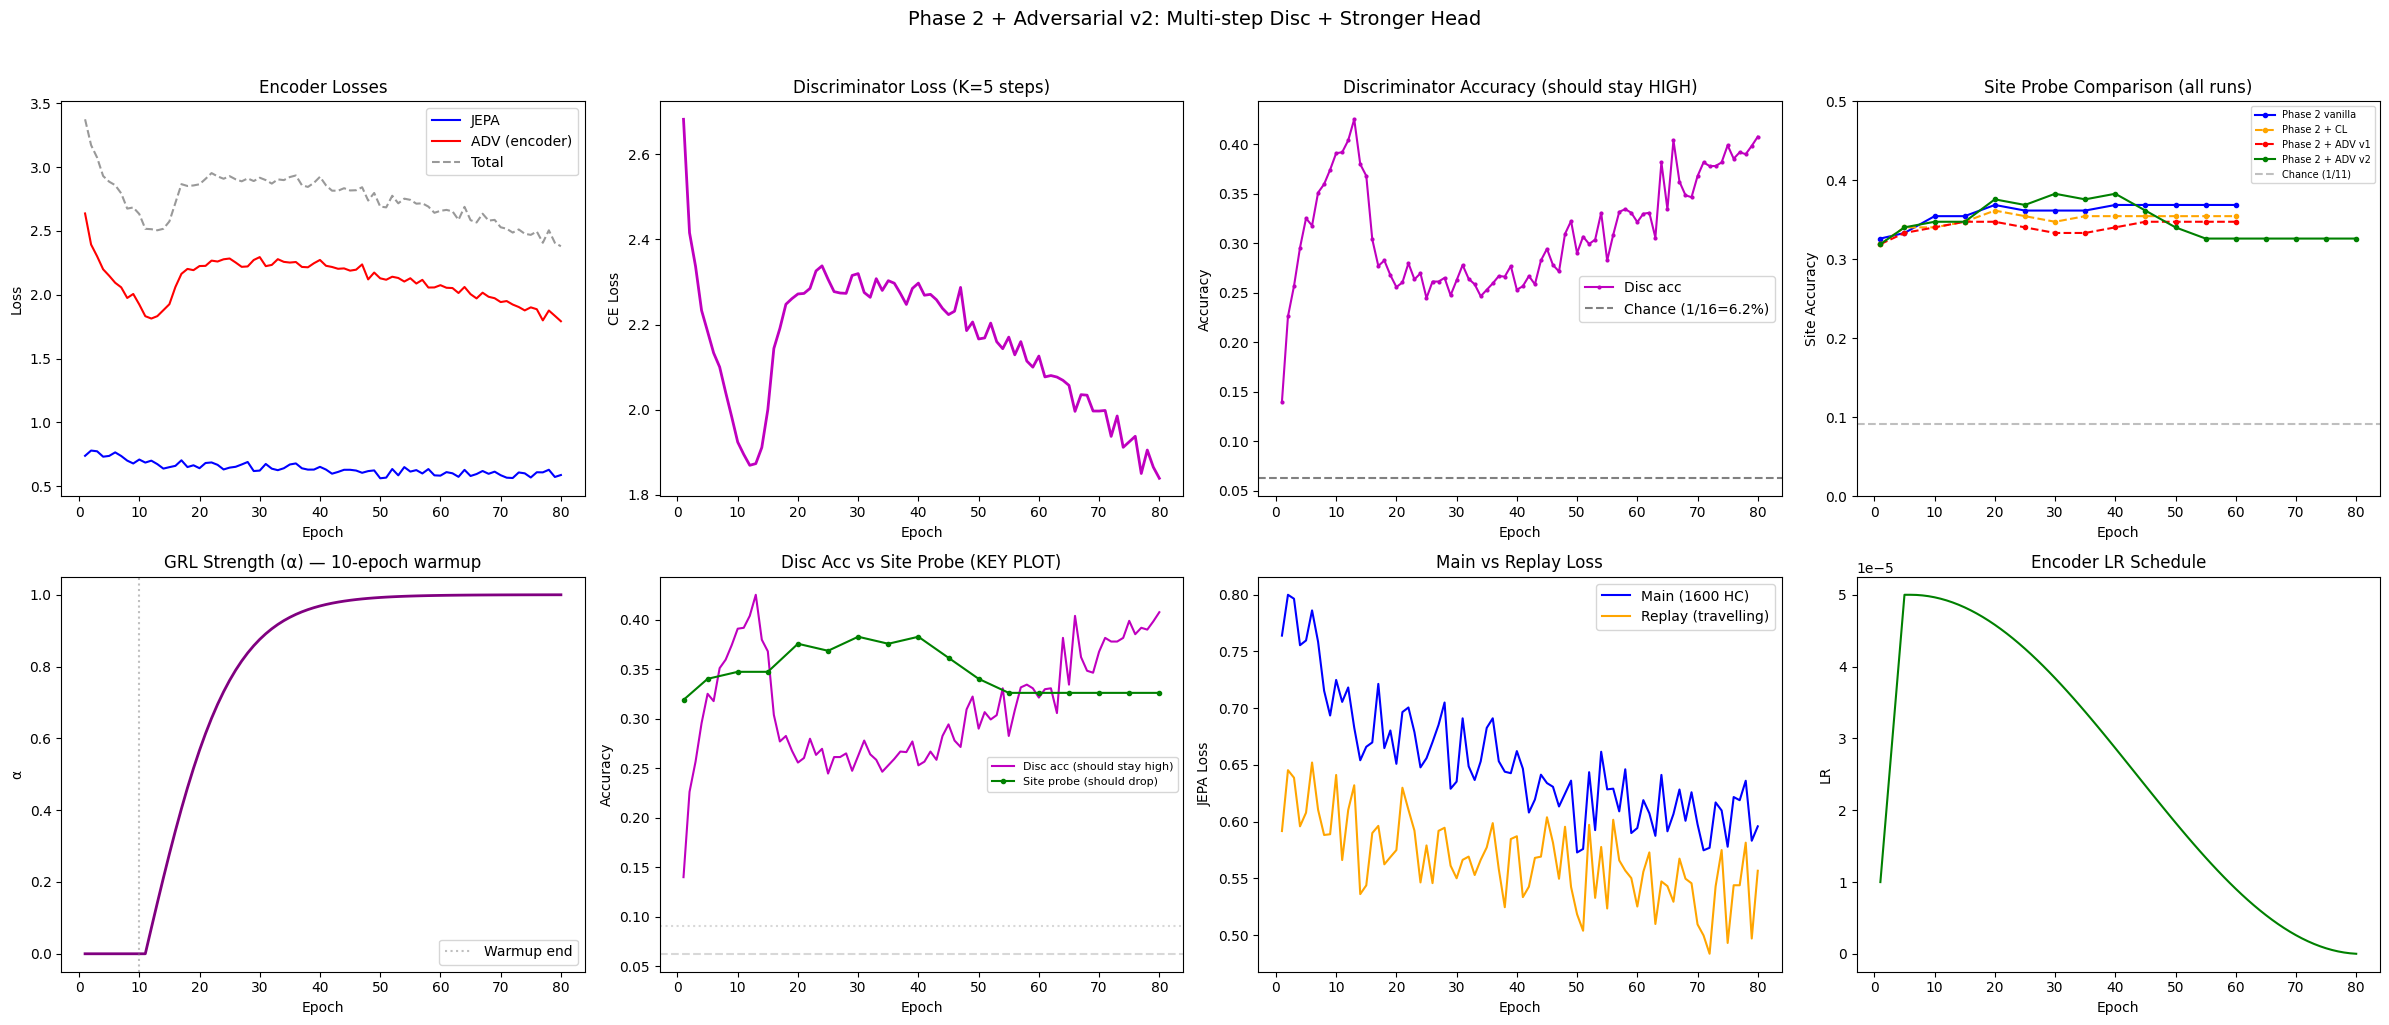


Final JEPA loss:      0.5875
Final ADV loss:       1.7927
Final disc loss:      1.8385
Final disc acc:       40.8%
Final α:              1.000
Final site probe:     32.6%
Best site probe:      31.9% (epoch 1)

v1 collapsed if: disc_acc ≈ chance AND site_probe ≈ 34%
v2 success if:   disc_acc >> chance AND site_probe << 34%


In [14]:
import json
import matplotlib.pyplot as plt
import numpy as np

hist = json.load(open('checkpoints/phase2_adversarial_v2/history_phase2advv2.json'))

fig, axes = plt.subplots(2, 4, figsize=(24, 10))

# 1. JEPA vs ADV loss (encoder's view)
axes[0, 0].plot(hist['epoch'], hist['jepa_loss'], 'b-', label='JEPA')
axes[0, 0].plot(hist['epoch'], hist['adv_loss'], 'r-', label='ADV (encoder)')
axes[0, 0].plot(hist['epoch'], hist['train_loss'], 'k--', alpha=0.4, label='Total')
axes[0, 0].set_xlabel('Epoch'); axes[0, 0].set_ylabel('Loss')
axes[0, 0].set_title('Encoder Losses'); axes[0, 0].legend()

# 2. Discriminator loss (separate from encoder)
axes[0, 1].plot(hist['epoch'], hist['disc_loss'], 'm-', linewidth=2)
axes[0, 1].set_xlabel('Epoch'); axes[0, 1].set_ylabel('CE Loss')
axes[0, 1].set_title('Discriminator Loss (K=5 steps)')

# 3. Discriminator accuracy — should STAY HIGH (not collapse like v1)
axes[0, 2].plot(hist['epoch'], hist['disc_accuracy'], 'm-o', markersize=2, label='Disc acc')
axes[0, 2].axhline(y=1/16, color='gray', linestyle='--', label=f'Chance (1/16={1/16:.1%})')
axes[0, 2].set_xlabel('Epoch'); axes[0, 2].set_ylabel('Accuracy')
axes[0, 2].set_title('Discriminator Accuracy (should stay HIGH)'); axes[0, 2].legend()

# 4. Site probe — compare ALL experiments
axes[0, 3].set_title('Site Probe Comparison (all runs)')
for name, path, color, ls in [
    ('Phase 2 vanilla', 'checkpoints/phase2/history_phase2.json', 'blue', '-'),
    ('Phase 2 + CL', 'checkpoints/phase2_contrastive/history_phase2cl.json', 'orange', '--'),
    ('Phase 2 + ADV v1', 'checkpoints/phase2_adversarial/history_phase2adv.json', 'red', '--'),
    ('Phase 2 + ADV v2', 'checkpoints/phase2_adversarial_v2/history_phase2advv2.json', 'green', '-'),
]:
    h = json.load(open(path))
    eps = [e for e, a in zip(h['epoch'], h['site_probe_accuracy']) if a is not None]
    acs = [a for a in h['site_probe_accuracy'] if a is not None]
    axes[0, 3].plot(eps, acs, 'o-', color=color, linestyle=ls, label=name, markersize=3)
axes[0, 3].axhline(y=1/11, color='gray', linestyle='--', alpha=0.5, label='Chance (1/11)')
axes[0, 3].set_xlabel('Epoch'); axes[0, 3].set_ylabel('Site Accuracy')
axes[0, 3].set_ylim(0, 0.5); axes[0, 3].legend(fontsize=7)

# 5. Alpha schedule (with warmup visible)
axes[1, 0].plot(hist['epoch'], hist['alpha'], 'purple', linewidth=2)
axes[1, 0].axvline(x=10, color='gray', linestyle=':', alpha=0.5, label='Warmup end')
axes[1, 0].set_xlabel('Epoch'); axes[1, 0].set_ylabel('α')
axes[1, 0].set_title('GRL Strength (α) — 10-epoch warmup'); axes[1, 0].legend()

# 6. Disc acc vs Site probe (the key diagnostic)
eps_p = [e for e, a in zip(hist['epoch'], hist['site_probe_accuracy']) if a is not None]
acs_p = [a for a in hist['site_probe_accuracy'] if a is not None]
axes[1, 1].plot(hist['epoch'], hist['disc_accuracy'], 'm-', label='Disc acc (should stay high)')
axes[1, 1].plot(eps_p, acs_p, 'g-o', markersize=3, label='Site probe (should drop)')
axes[1, 1].axhline(y=1/16, color='gray', linestyle='--', alpha=0.3)
axes[1, 1].axhline(y=1/11, color='gray', linestyle=':', alpha=0.3)
axes[1, 1].set_xlabel('Epoch'); axes[1, 1].set_ylabel('Accuracy')
axes[1, 1].set_title('Disc Acc vs Site Probe (KEY PLOT)'); axes[1, 1].legend(fontsize=8)

# 7. Main vs Replay JEPA loss
axes[1, 2].plot(hist['epoch'], hist['main_loss'], 'b-', label='Main (1600 HC)')
axes[1, 2].plot(hist['epoch'], hist['replay_loss'], 'orange', label='Replay (travelling)')
axes[1, 2].set_xlabel('Epoch'); axes[1, 2].set_ylabel('JEPA Loss')
axes[1, 2].set_title('Main vs Replay Loss'); axes[1, 2].legend()

# 8. LR schedule
axes[1, 3].plot(hist['epoch'], hist['learning_rate'], 'green')
axes[1, 3].set_xlabel('Epoch'); axes[1, 3].set_ylabel('LR')
axes[1, 3].set_title('Encoder LR Schedule')

plt.suptitle('Phase 2 + Adversarial v2: Multi-step Disc + Stronger Head', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('checkpoints/phase2_adversarial_v2/training_curves_phase2advv2.png', dpi=300, bbox_inches='tight')
plt.show()

# Key numbers
print(f"\nFinal JEPA loss:      {hist['jepa_loss'][-1]:.4f}")
print(f"Final ADV loss:       {hist['adv_loss'][-1]:.4f}")
print(f"Final disc loss:      {hist['disc_loss'][-1]:.4f}")
print(f"Final disc acc:       {hist['disc_accuracy'][-1]:.1%}")
print(f"Final α:              {hist['alpha'][-1]:.3f}")
print(f"Final site probe:     {acs_p[-1]:.1%}")
print(f"Best site probe:      {min(acs_p):.1%} (epoch {eps_p[acs_p.index(min(acs_p))]})")
print(f"\nv1 collapsed if: disc_acc ≈ chance AND site_probe ≈ 34%")
print(f"v2 success if:   disc_acc >> chance AND site_probe << 34%")

/tmp/ipykernel_3677172/110469266.py:26: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  axes[0, 1].plot(eps, acs, 'o-', color=color, linestyle=ls, label=name)


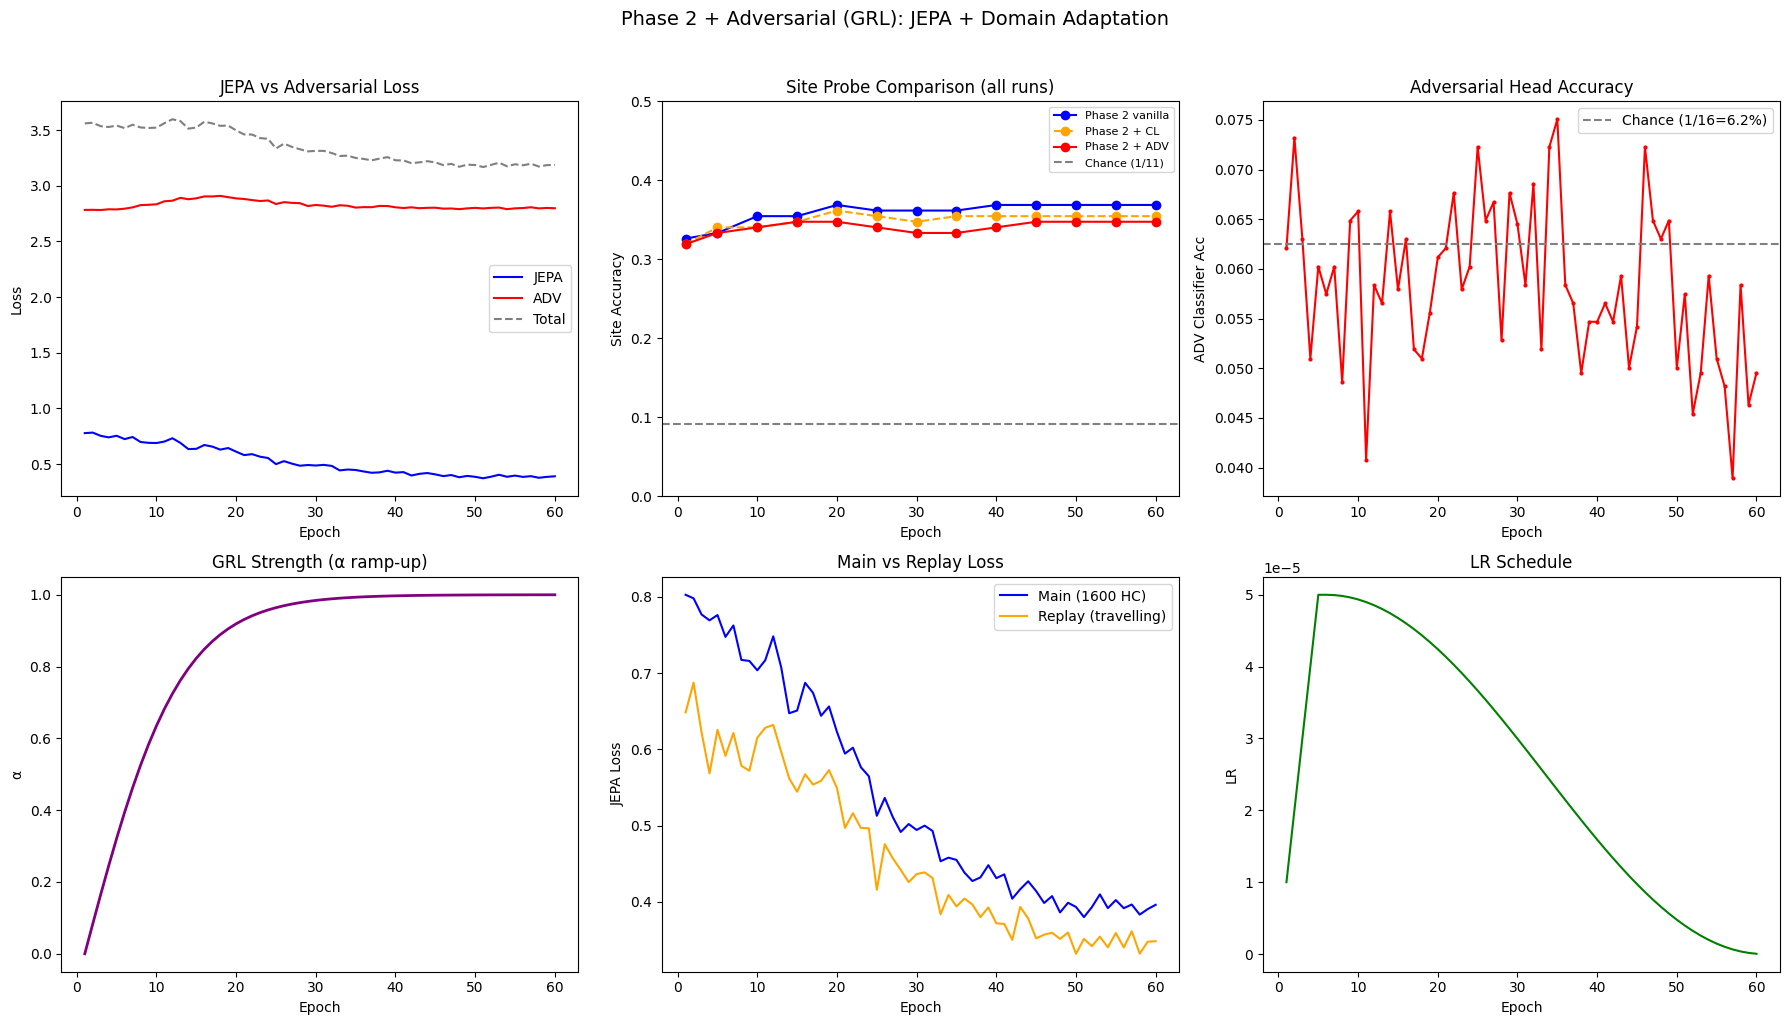


Final JEPA loss:      0.3897
Final ADV loss:       2.7980
Final ADV acc:        5.0%
Final α:              1.000
Final site probe:     34.8%
Best site probe:      31.9% (epoch 1)


In [13]:
import json
import matplotlib.pyplot as plt
import numpy as np

hist = json.load(open('checkpoints/phase2_adversarial/history_phase2adv.json'))

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Total = JEPA + λ·ADV
axes[0, 0].plot(hist['epoch'], hist['jepa_loss'], 'b-', label='JEPA')
axes[0, 0].plot(hist['epoch'], hist['adv_loss'], 'r-', label='ADV')
axes[0, 0].plot(hist['epoch'], hist['train_loss'], 'k--', alpha=0.5, label='Total')
axes[0, 0].set_xlabel('Epoch'); axes[0, 0].set_ylabel('Loss')
axes[0, 0].set_title('JEPA vs Adversarial Loss'); axes[0, 0].legend()

# 2. Site probe — ALL experiments compared
axes[0, 1].set_title('Site Probe Comparison (all runs)')
for name, path, color, ls in [
    ('Phase 2 vanilla', 'checkpoints/phase2/history_phase2.json', 'blue', '-'),
    ('Phase 2 + CL', 'checkpoints/phase2_contrastive/history_phase2cl.json', 'orange', '--'),
    ('Phase 2 + ADV', 'checkpoints/phase2_adversarial/history_phase2adv.json', 'red', '-'),
]:
    h = json.load(open(path))
    eps = [e for e, a in zip(h['epoch'], h['site_probe_accuracy']) if a is not None]
    acs = [a for a in h['site_probe_accuracy'] if a is not None]
    axes[0, 1].plot(eps, acs, 'o-', color=color, linestyle=ls, label=name)
axes[0, 1].axhline(y=1/11, color='gray', linestyle='--', label='Chance (1/11)')
axes[0, 1].set_xlabel('Epoch'); axes[0, 1].set_ylabel('Site Accuracy')
axes[0, 1].set_ylim(0, 0.5); axes[0, 1].legend(fontsize=8)

# 3. ADV classifier accuracy (should DROP as GRL kicks in)
axes[0, 2].plot(hist['epoch'], hist['adv_site_accuracy'], 'r-o', markersize=2)
axes[0, 2].axhline(y=1/16, color='gray', linestyle='--', label=f'Chance (1/16={1/16:.1%})')
axes[0, 2].set_xlabel('Epoch'); axes[0, 2].set_ylabel('ADV Classifier Acc')
axes[0, 2].set_title('Adversarial Head Accuracy'); axes[0, 2].legend()

# 4. Alpha schedule (GRL strength ramp-up)
axes[1, 0].plot(hist['epoch'], hist['alpha'], 'purple', linewidth=2)
axes[1, 0].set_xlabel('Epoch'); axes[1, 0].set_ylabel('α')
axes[1, 0].set_title('GRL Strength (α ramp-up)')

# 5. Main vs Replay JEPA loss
axes[1, 1].plot(hist['epoch'], hist['main_loss'], 'b-', label='Main (1600 HC)')
axes[1, 1].plot(hist['epoch'], hist['replay_loss'], 'orange', label='Replay (travelling)')
axes[1, 1].set_xlabel('Epoch'); axes[1, 1].set_ylabel('JEPA Loss')
axes[1, 1].set_title('Main vs Replay Loss'); axes[1, 1].legend()

# 6. LR
axes[1, 2].plot(hist['epoch'], hist['learning_rate'], 'green')
axes[1, 2].set_xlabel('Epoch'); axes[1, 2].set_ylabel('LR')
axes[1, 2].set_title('LR Schedule')

plt.suptitle('Phase 2 + Adversarial (GRL): JEPA + Domain Adaptation', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('checkpoints/phase2_adversarial/training_curves_phase2adv.png', dpi=300, bbox_inches='tight')
plt.show()

# Key numbers
eps_p = [e for e, a in zip(hist['epoch'], hist['site_probe_accuracy']) if a is not None]
acs_p = [a for a in hist['site_probe_accuracy'] if a is not None]
print(f"\nFinal JEPA loss:      {hist['jepa_loss'][-1]:.4f}")
print(f"Final ADV loss:       {hist['adv_loss'][-1]:.4f}")
print(f"Final ADV acc:        {hist['adv_site_accuracy'][-1]:.1%}")
print(f"Final α:              {hist['alpha'][-1]:.3f}")
print(f"Final site probe:     {acs_p[-1]:.1%}")
print(f"Best site probe:      {min(acs_p):.1%} (epoch {eps_p[acs_p.index(min(acs_p))]})")

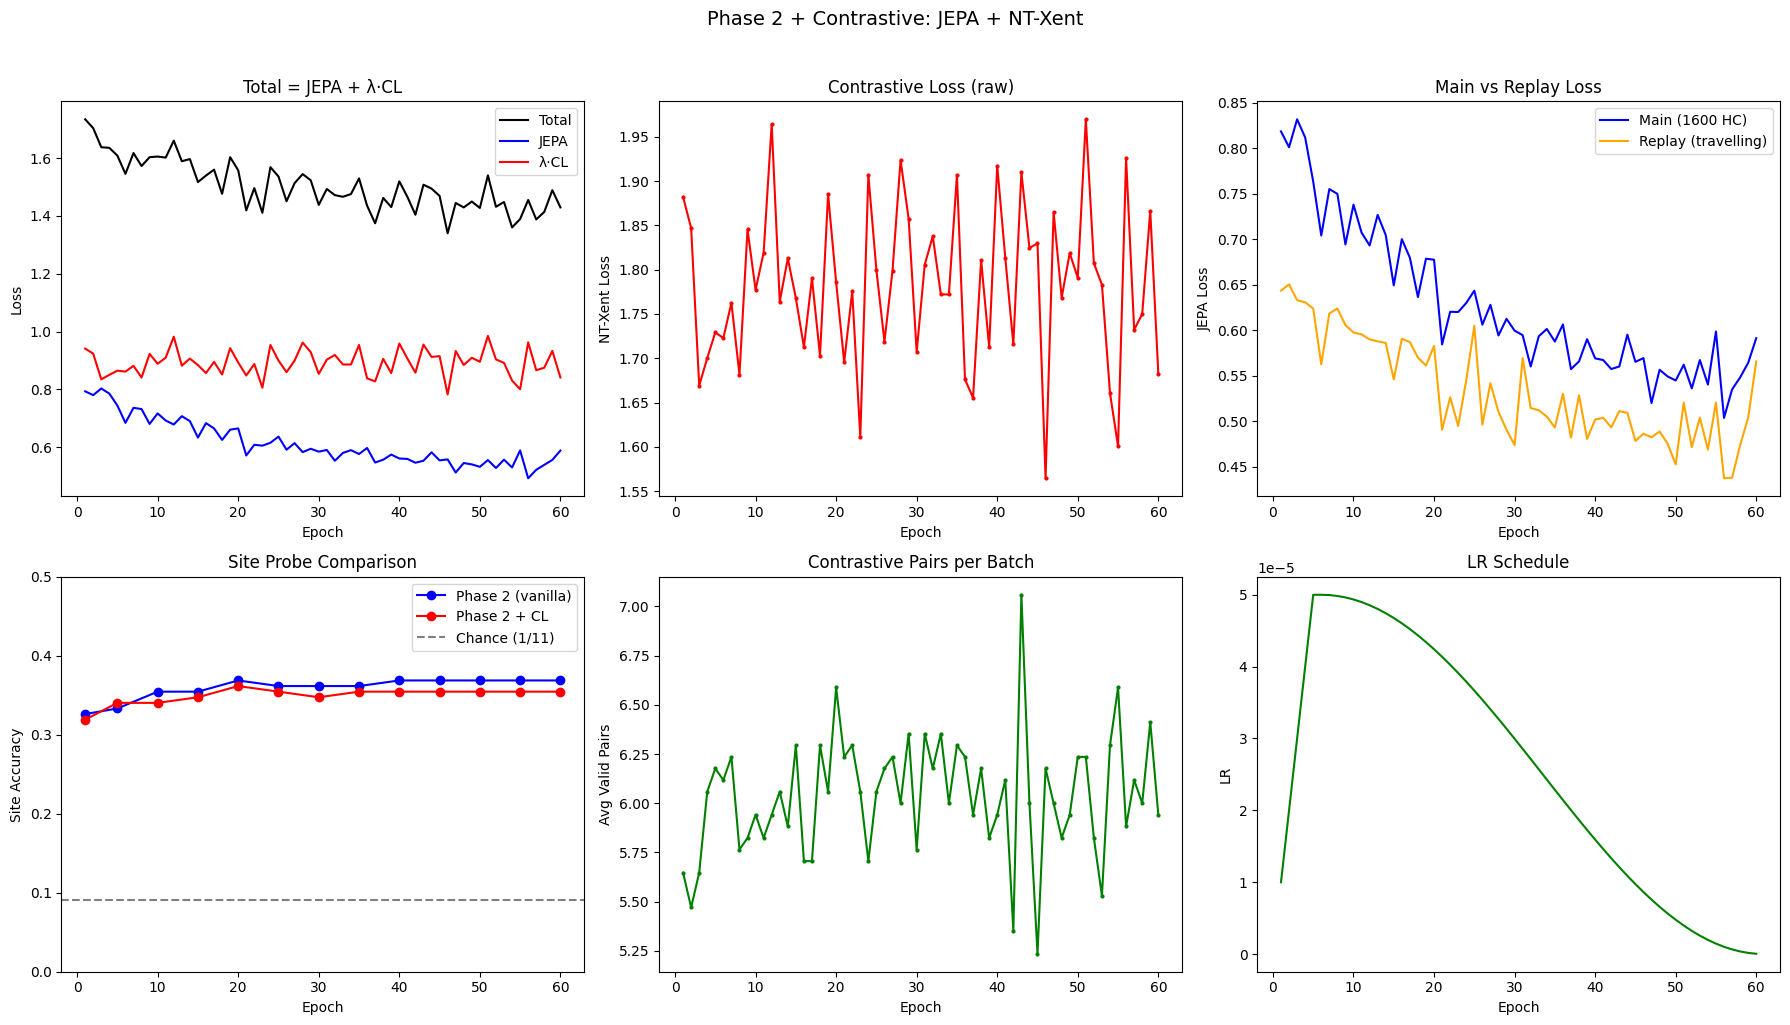


Final JEPA loss:        0.5882
Final CL loss:          1.6823
Final main loss:        0.5915
Final replay loss:      0.5659
Final site probe:       35.5%
Avg pairs per batch:    5.9


In [12]:
import json
import matplotlib.pyplot as plt

hist = json.load(open('checkpoints/phase2_contrastive/history_phase2cl.json'))

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Total loss
axes[0, 0].plot(hist['epoch'], hist['train_loss'], 'k-', label='Total')
axes[0, 0].plot(hist['epoch'], hist['jepa_loss'], 'b-', label='JEPA')
axes[0, 0].plot(hist['epoch'], [cfg * cl for cfg, cl in zip([0.5]*len(hist['contrastive_loss']), hist['contrastive_loss'])], 'r-', label='λ·CL')
axes[0, 0].set_xlabel('Epoch'); axes[0, 0].set_ylabel('Loss')
axes[0, 0].set_title('Total = JEPA + λ·CL'); axes[0, 0].legend()

# 2. Contrastive loss alone
axes[0, 1].plot(hist['epoch'], hist['contrastive_loss'], 'r-o', markersize=2)
axes[0, 1].set_xlabel('Epoch'); axes[0, 1].set_ylabel('NT-Xent Loss')
axes[0, 1].set_title('Contrastive Loss (raw)')

# 3. Main vs Replay JEPA loss
axes[0, 2].plot(hist['epoch'], hist['main_loss'], 'b-', label='Main (1600 HC)')
axes[0, 2].plot(hist['epoch'], hist['replay_loss'], 'orange', label='Replay (travelling)')
axes[0, 2].set_xlabel('Epoch'); axes[0, 2].set_ylabel('JEPA Loss')
axes[0, 2].set_title('Main vs Replay Loss'); axes[0, 2].legend()

# 4. Site probe — compare Phase 2 vanilla vs contrastive
axes[1, 0].set_title('Site Probe Comparison')
for name, path, color in [
    ('Phase 2 (vanilla)', 'checkpoints/phase2/history_phase2.json', 'blue'),
    ('Phase 2 + CL', 'checkpoints/phase2_contrastive/history_phase2cl.json', 'red'),
]:
    h = json.load(open(path))
    eps = [e for e, a in zip(h['epoch'], h['site_probe_accuracy']) if a is not None]
    acs = [a for a in h['site_probe_accuracy'] if a is not None]
    axes[1, 0].plot(eps, acs, 'o-', color=color, label=name)
axes[1, 0].axhline(y=1/11, color='gray', linestyle='--', label='Chance (1/11)')
axes[1, 0].set_xlabel('Epoch'); axes[1, 0].set_ylabel('Site Accuracy')
axes[1, 0].set_ylim(0, 0.5); axes[1, 0].legend()

# 5. Valid pairs per batch
axes[1, 1].plot(hist['epoch'], hist['n_valid_pairs'], 'g-o', markersize=2)
axes[1, 1].set_xlabel('Epoch'); axes[1, 1].set_ylabel('Avg Valid Pairs')
axes[1, 1].set_title('Contrastive Pairs per Batch')

# 6. LR
axes[1, 2].plot(hist['epoch'], hist['learning_rate'], 'green')
axes[1, 2].set_xlabel('Epoch'); axes[1, 2].set_ylabel('LR')
axes[1, 2].set_title('LR Schedule')

plt.suptitle('Phase 2 + Contrastive: JEPA + NT-Xent', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('checkpoints/phase2_contrastive/training_curves_phase2cl.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\nFinal JEPA loss:        {hist['jepa_loss'][-1]:.4f}")
print(f"Final CL loss:          {hist['contrastive_loss'][-1]:.4f}")
print(f"Final main loss:        {hist['main_loss'][-1]:.4f}")
print(f"Final replay loss:      {hist['replay_loss'][-1]:.4f}")
eps_p = [e for e, a in zip(hist['epoch'], hist['site_probe_accuracy']) if a is not None]
acs_p = [a for a in hist['site_probe_accuracy'] if a is not None]
print(f"Final site probe:       {acs_p[-1]:.1%}")
print(f"Avg pairs per batch:    {hist['n_valid_pairs'][-1]:.1f}")

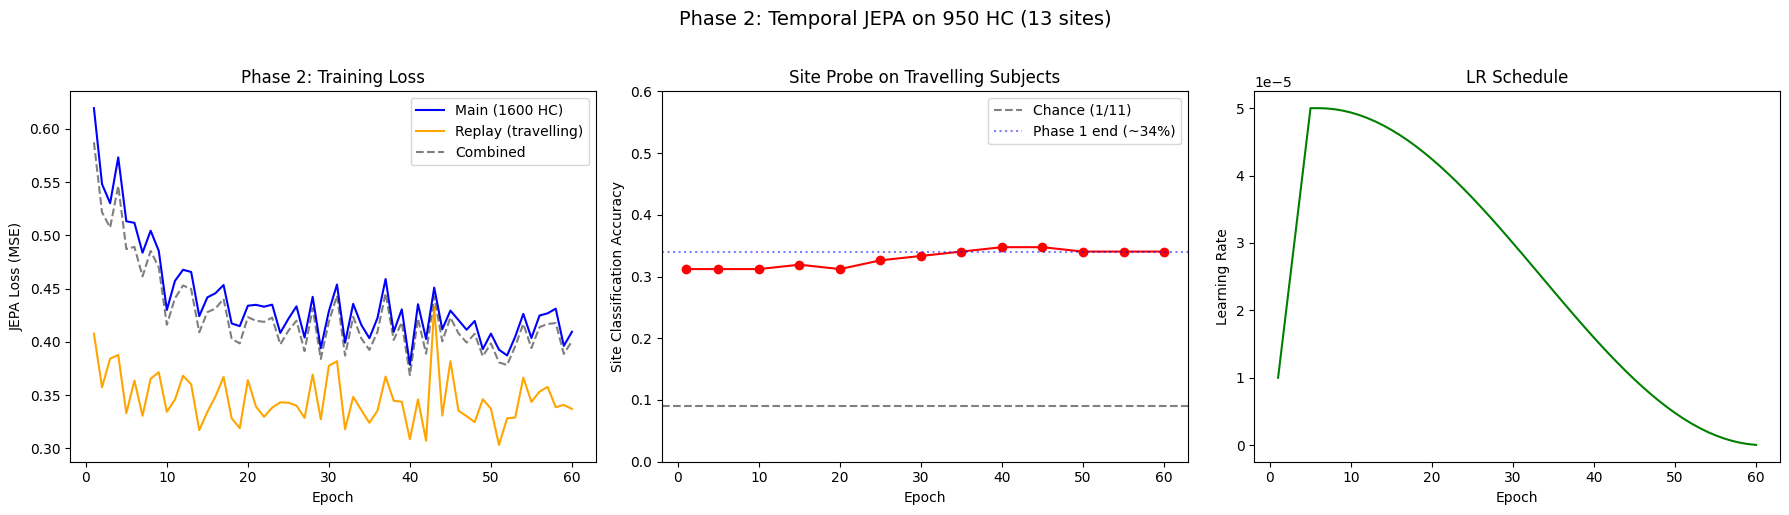


Final main loss:   0.4094
Final replay loss: 0.3371
Final site probe:  34.0%
Loss gap (replay - main): -0.0724


In [11]:
import json
import matplotlib.pyplot as plt

hist = json.load(open('checkpoints/phase2/history_phase2.json'))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Loss curves (main vs replay)
axes[0].plot(hist['epoch'], hist['main_loss'], label='Main (1600 HC)', color='blue')
axes[0].plot(hist['epoch'], hist['replay_loss'], label='Replay (travelling)', color='orange')
axes[0].plot(hist['epoch'], hist['train_loss'], label='Combined', color='black', linestyle='--', alpha=0.5)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('JEPA Loss (MSE)')
axes[0].set_title('Phase 2: Training Loss')
axes[0].legend()

# 2. Site probe
epochs_p = [e for e, a in zip(hist['epoch'], hist['site_probe_accuracy']) if a is not None]
accs = [a for a in hist['site_probe_accuracy'] if a is not None]
axes[1].plot(epochs_p, accs, 'o-', color='red')
axes[1].axhline(y=1/11, color='gray', linestyle='--', label='Chance (1/11)')
axes[1].axhline(y=0.34, color='blue', linestyle=':', alpha=0.5, label='Phase 1 end (~34%)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Site Classification Accuracy')
axes[1].set_title('Site Probe on Travelling Subjects')
axes[1].set_ylim(0, 0.6)
axes[1].legend()

# 3. LR schedule
axes[2].plot(hist['epoch'], hist['learning_rate'], color='green')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Learning Rate')
axes[2].set_title('LR Schedule')

plt.suptitle('Phase 2: Temporal JEPA on 950 HC (13 sites)', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('checkpoints/phase2/training_curves_phase2.png', dpi=300, bbox_inches='tight')
plt.show()

# Print key numbers
print(f"\nFinal main loss:   {hist['main_loss'][-1]:.4f}")
print(f"Final replay loss: {hist['replay_loss'][-1]:.4f}")
print(f"Final site probe:  {accs[-1]:.1%}")
print(f"Loss gap (replay - main): {hist['replay_loss'][-1] - hist['main_loss'][-1]:.4f}")

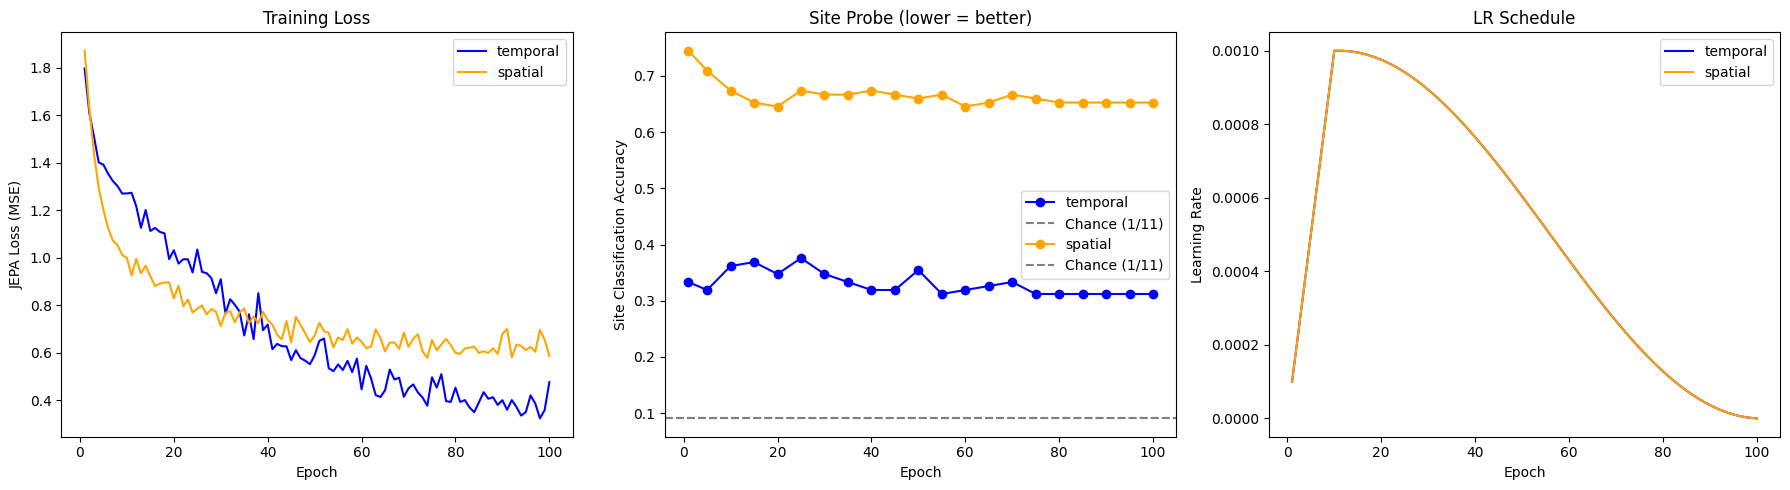

In [10]:
import json
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for mode, color in [('temporal', 'blue'), ('spatial', 'orange')]:
    hist = json.load(open(f'checkpoints/phase1/history_{mode}.json'))
    
    # 1. Loss curve
    axes[0].plot(hist['epoch'], hist['train_loss'], color=color, label=f'{mode}')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('JEPA Loss (MSE)')
    axes[0].set_title('Training Loss')
    axes[0].legend()
    
    # 2. Site probe accuracy
    epochs_with_probe = [e for e, a in zip(hist['epoch'], hist['site_probe_accuracy']) if a is not None]
    accs = [a for a in hist['site_probe_accuracy'] if a is not None]
    axes[1].plot(epochs_with_probe, accs, color=color, marker='o', label=f'{mode}')
    axes[1].axhline(y=1/11, color='gray', linestyle='--', label='Chance (1/11)')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Site Classification Accuracy')
    axes[1].set_title('Site Probe (lower = better)')
    axes[1].legend()
    
    # 3. Learning rate
    axes[2].plot(hist['epoch'], hist['learning_rate'], color=color, label=f'{mode}')
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylabel('Learning Rate')
    axes[2].set_title('LR Schedule')
    axes[2].legend()

plt.tight_layout()
plt.savefig('checkpoints/phase1/training_curves.png', dpi=300)
plt.show()

In [6]:
from jepa.masking import generate_temporal_mask, generate_spatial_mask
from jepa.model import JEPA
import torch
import torch.nn as nn
# Model A — Temporal: tokens are time steps
model_A = JEPA(
    input_dim=400,       # each time step token has 400 parcel values
    max_seq_len=93,      # 93 time steps
    embed_dim=256,
    encoder_depth=6,
    predictor_depth=2,
    num_heads=8,
)

# Model B — Spatial: tokens are parcels
model_B = JEPA(
    input_dim=93,        # each parcel token has 93 time step values
    max_seq_len=400,     # 400 parcels
    embed_dim=256,
    encoder_depth=6,
    predictor_depth=2,
    num_heads=8,
)

# Quick check
print(f"Model A params: {sum(p.numel() for p in model_A.parameters() if p.requires_grad):,}")
print(f"Model B params: {sum(p.numel() for p in model_B.parameters() if p.requires_grad):,}")

from jepa.masking import generate_temporal_mask, generate_spatial_mask

# Test Model A (temporal)
batch = torch.randn(4, 93, 400)           # fake batch of 4 samples
ctx_idx, tgt_idx = generate_temporal_mask(93)
pred_A, target_A = model_A(batch, ctx_idx, tgt_idx)
print(f"Model A — predicted: {pred_A.shape}, target: {target_A.shape}")
# Should be: (4, ~20-25, 256) and (4, ~20-25, 256)

# Test Model B (spatial)
batch_s = torch.randn(4, 400, 93)
ctx_idx_s, tgt_idx_s = generate_spatial_mask(400)
pred_B, target_B = model_B(batch_s, ctx_idx_s, tgt_idx_s)
print(f"Model B — predicted: {pred_B.shape}, target: {target_B.shape}")
# Should be: (4, ~80-120, 256) and (4, ~80-120, 256)

# The loss would be:
loss = nn.functional.mse_loss(pred_A, target_A)
print(f"Sample loss: {loss.item():.4f}")

Model A params: 6,469,632
Model B params: 6,548,224
Model A — predicted: torch.Size([4, 29, 256]), target: torch.Size([4, 29, 256])


/home/s.dharia-ra/miniconda3/envs/ml/lib/python3.10/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


[get_dataset_dir] Dataset found in /home/s.dharia-ra/nilearn_data/schaefer_2018

Model B — predicted: torch.Size([4, 138, 256]), target: torch.Size([4, 138, 256])
Sample loss: 1.9308


Subject: sub-01, Site: ATT
Temporal tensor: torch.Size([93, 400])
Spatial  tensor: torch.Size([400, 93])


[get_dataset_dir] Dataset found in /home/s.dharia-ra/nilearn_data/schaefer_2018


Temporal mask: 67 context + 26 target = 93
Spatial  mask: 277 context + 123 target = 400


[get_dataset_dir] Dataset found in /home/s.dharia-ra/nilearn_data/schaefer_2018

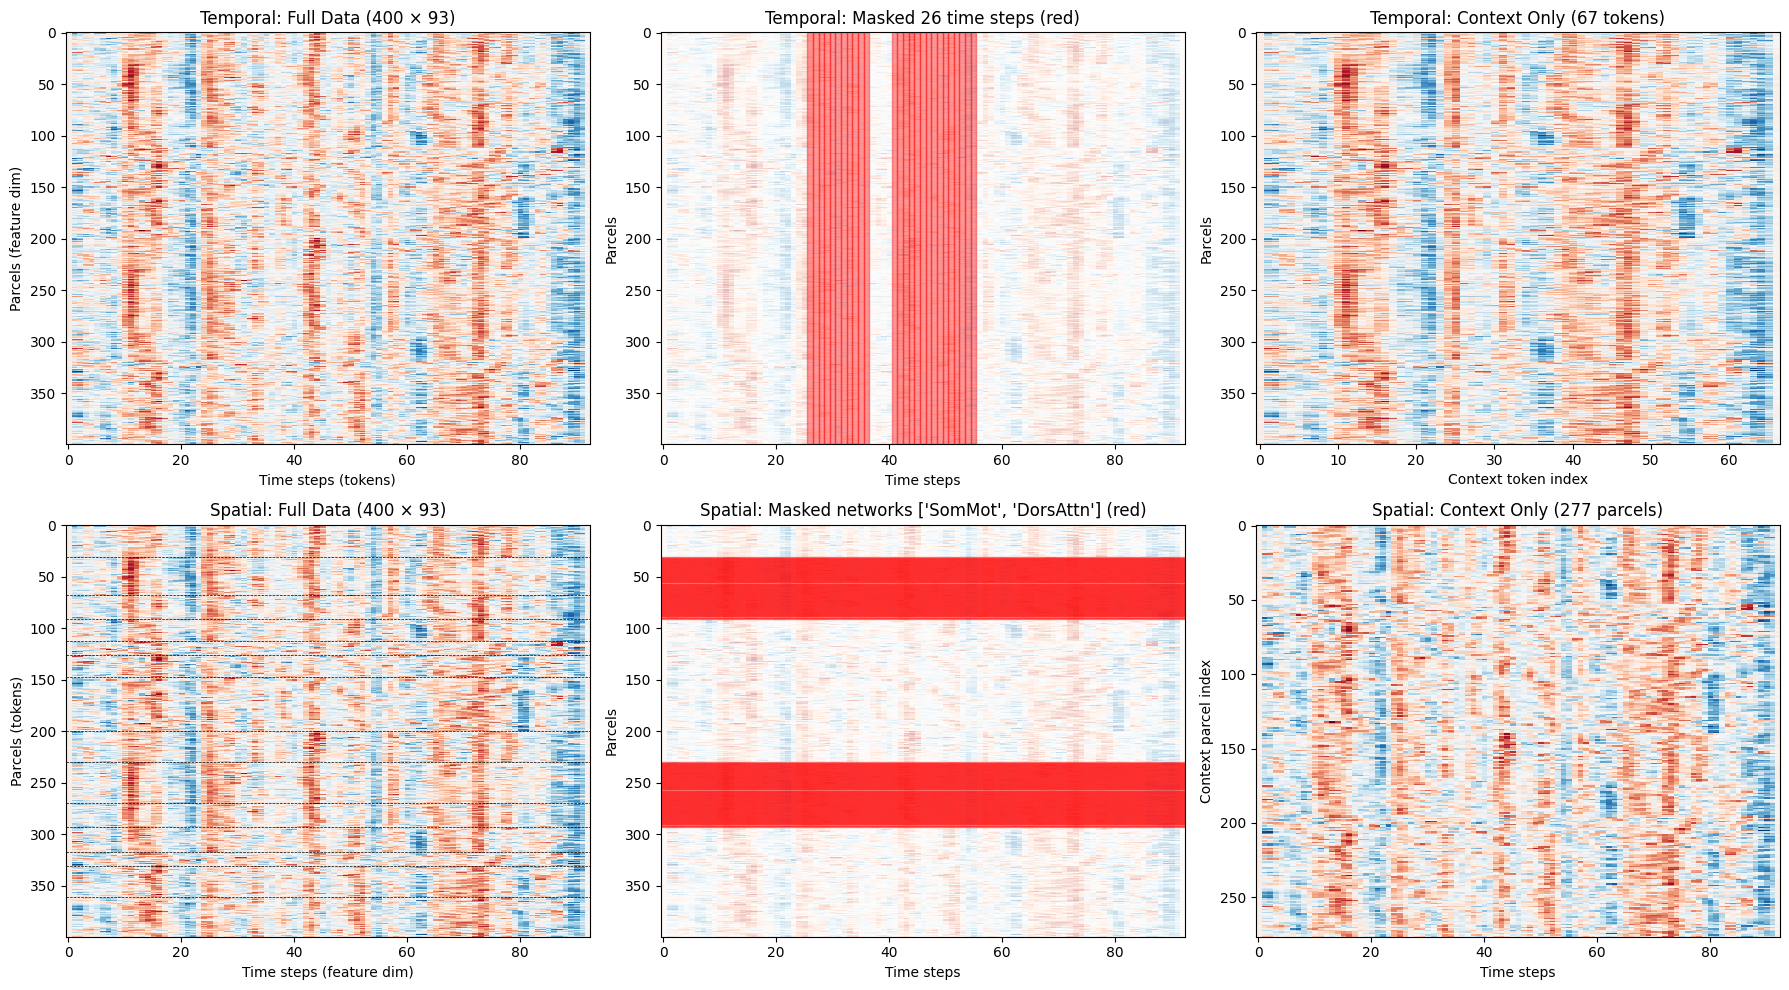


✓ Saved to masking_visualization.png


In [2]:
import sys
sys.path.insert(0, 'src')

import numpy as np
import matplotlib.pyplot as plt
from jepa.dataset import FMRIDataset
from jepa.masking import generate_temporal_mask, generate_spatial_mask, get_schaefer400_network_labels

# ── Load one sample in both modes ──
TRAVELING_DIR = "preprocessed_data_fir/roi_timeseries_traveling"

ds_temporal = FMRIDataset(TRAVELING_DIR, tokenization_mode='temporal')
ds_spatial  = FMRIDataset(TRAVELING_DIR, tokenization_mode='spatial')

ts_t, labels_t = ds_temporal[0]   # (93, 400)
ts_s, labels_s = ds_spatial[0]    # (400, 93)

print(f"Subject: {labels_t['subject']}, Site: {labels_t['site']}")
print(f"Temporal tensor: {ts_t.shape}")
print(f"Spatial  tensor: {ts_s.shape}")

# ── Generate masks ──
ctx_t, tgt_t = generate_temporal_mask(seq_len=93, num_blocks=2, block_size_range=(10, 15))
ctx_s, tgt_s = generate_spatial_mask(seq_len=400, num_networks_to_mask=2)

print(f"\nTemporal mask: {len(ctx_t)} context + {len(tgt_t)} target = {len(ctx_t)+len(tgt_t)}")
print(f"Spatial  mask: {len(ctx_s)} context + {len(tgt_s)} target = {len(ctx_s)+len(tgt_s)}")

# ── Visualization ──
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# ===== ROW 1: TEMPORAL =====
data_t = ts_t.numpy()  # (93, 400)

# 1a. Full temporal matrix
axes[0, 0].imshow(data_t.T, aspect='auto', cmap='RdBu_r', interpolation='none')
axes[0, 0].set_title('Temporal: Full Data (400 × 93)')
axes[0, 0].set_xlabel('Time steps (tokens)')
axes[0, 0].set_ylabel('Parcels (feature dim)')

# 1b. Show which timepoints are masked
mask_img_t = np.zeros(93)
mask_img_t[tgt_t.numpy()] = 1
axes[0, 1].imshow(data_t.T, aspect='auto', cmap='RdBu_r', interpolation='none', alpha=0.3)
# Overlay red bands for masked regions
for idx in tgt_t.numpy():
    axes[0, 1].axvspan(idx - 0.5, idx + 0.5, color='red', alpha=0.4)
axes[0, 1].set_title(f'Temporal: Masked {len(tgt_t)} time steps (red)')
axes[0, 1].set_xlabel('Time steps')
axes[0, 1].set_ylabel('Parcels')

# 1c. Context only (what the encoder sees)
context_data_t = data_t[ctx_t.numpy(), :]  # (num_context, 400)
axes[0, 2].imshow(context_data_t.T, aspect='auto', cmap='RdBu_r', interpolation='none')
axes[0, 2].set_title(f'Temporal: Context Only ({len(ctx_t)} tokens)')
axes[0, 2].set_xlabel('Context token index')
axes[0, 2].set_ylabel('Parcels')

# ===== ROW 2: SPATIAL =====
data_s = ts_s.numpy()  # (400, 93)
net_labels = get_schaefer400_network_labels()
net_names = {1: 'Vis', 2: 'SomMot', 3: 'DorsAttn', 4: 'SalVentAttn',
             5: 'Limbic', 6: 'Cont', 7: 'Default'}

# 2a. Full spatial matrix with network boundaries
axes[1, 0].imshow(data_s, aspect='auto', cmap='RdBu_r', interpolation='none')
# Draw network boundary lines
prev = net_labels[0]
for i in range(1, 400):
    if net_labels[i] != prev:
        axes[1, 0].axhline(y=i - 0.5, color='black', linewidth=0.5, linestyle='--')
        prev = net_labels[i]
axes[1, 0].set_title('Spatial: Full Data (400 × 93)')
axes[1, 0].set_xlabel('Time steps (feature dim)')
axes[1, 0].set_ylabel('Parcels (tokens)')

# 2b. Show which parcels/networks are masked
axes[1, 1].imshow(data_s, aspect='auto', cmap='RdBu_r', interpolation='none', alpha=0.3)
for idx in tgt_s.numpy():
    axes[1, 1].axhspan(idx - 0.5, idx + 0.5, color='red', alpha=0.4)
# Label which networks were masked
masked_nets = sorted(set(net_labels[tgt_s.numpy()].tolist()))
masked_names = [net_names[n] for n in masked_nets]
axes[1, 1].set_title(f'Spatial: Masked networks {masked_names} (red)')
axes[1, 1].set_xlabel('Time steps')
axes[1, 1].set_ylabel('Parcels')

# 2c. Context only
context_data_s = data_s[ctx_s.numpy(), :]  # (num_context, 93)
axes[1, 2].imshow(context_data_s, aspect='auto', cmap='RdBu_r', interpolation='none')
axes[1, 2].set_title(f'Spatial: Context Only ({len(ctx_s)} parcels)')
axes[1, 2].set_xlabel('Time steps')
axes[1, 2].set_ylabel('Context parcel index')

plt.tight_layout()
plt.savefig('masking_visualization.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✓ Saved to masking_visualization.png")

In [5]:
import numpy as np
from nilearn.datasets import fetch_atlas_schaefer_2018

# ── 1. Load the EXACT atlas used during preprocessing ──
atlas = fetch_atlas_schaefer_2018(n_rois=400, resolution_mm=2)

# Labels come as bytes, decode to strings
labels = [lbl.decode('utf-8') if isinstance(lbl, bytes) else str(lbl)
          for lbl in atlas['labels']]

print(f"Total labels: {len(labels)}")
print(f"First 5: {labels[:5]}")
print(f"Last  5: {labels[-5:]}")

# ── 2. Parse the network name from each label ──
# Format: "7Networks_LH_Vis_1" → network = "Vis"
network_names = []
for lbl in labels:
    parts = lbl.split('_')
    # parts: ['7Networks', 'LH', 'Vis', '1']  or ['7Networks', 'RH', 'Default', 'PFC', '5']
    # The network name is parts[2], but some have sub-names like "SalVentAttn"
    # Safest: rejoin everything between hemisphere and the trailing number
    hemi_idx = 1          # 'LH' or 'RH'
    network = parts[2]    # This is the canonical network short name
    network_names.append(network)

# Map network short names to IDs
unique_networks = list(dict.fromkeys(network_names))  # preserves order of first appearance
print(f"\nOrdered unique networks: {unique_networks}")

name_to_id = {name: i+1 for i, name in enumerate(unique_networks)}
print(f"Network name → ID mapping: {name_to_id}")

# ── 3. Build ground-truth label array ──
atlas_network_ids = np.array([name_to_id[n] for n in network_names])
print(f"\nGround-truth array shape: {atlas_network_ids.shape}")

# ── 4. Count parcels per network ──
from collections import Counter
counts = Counter(network_names)
print("\nParcels per network (from atlas):")
for name in unique_networks:
    print(f"  {name_to_id[name]}. {name:20s} → {counts[name]} parcels")

# ── 5. Compare with our hardcoded version ──
def get_schaefer400_network_labels_hardcoded():
    network_sizes_per_hemi = [
        (1, 30), (2, 27), (3, 22), (4, 21), (5, 13), (6, 27), (7, 60),
    ]
    labels = []
    for _ in ['LH', 'RH']:
        for net_id, count in network_sizes_per_hemi:
            labels.extend([net_id] * count)
    return np.array(labels)

hardcoded = get_schaefer400_network_labels_hardcoded()

match = np.array_equal(atlas_network_ids, hardcoded)
print(f"\n{'✓ MATCH' if match else '✗ MISMATCH'}: hardcoded vs atlas ground truth")

if not match:
    mismatches = np.where(atlas_network_ids != hardcoded)[0]
    print(f"  Mismatches at {len(mismatches)} indices, first 10: {mismatches[:10]}")
    print(f"  Atlas   : {atlas_network_ids[mismatches[:10]]}")
    print(f"  Hardcode: {hardcoded[mismatches[:10]]}")

[get_dataset_dir] Dataset found in /home/s.dharia-ra/nilearn_data/schaefer_2018

Total labels: 400
First 5: ['7Networks_LH_Vis_1', '7Networks_LH_Vis_2', '7Networks_LH_Vis_3', '7Networks_LH_Vis_4', '7Networks_LH_Vis_5']
Last  5: ['7Networks_RH_Default_pCunPCC_5', '7Networks_RH_Default_pCunPCC_6', '7Networks_RH_Default_pCunPCC_7', '7Networks_RH_Default_pCunPCC_8', '7Networks_RH_Default_pCunPCC_9']

Ordered unique networks: ['Vis', 'SomMot', 'DorsAttn', 'SalVentAttn', 'Limbic', 'Cont', 'Default']
Network name → ID mapping: {'Vis': 1, 'SomMot': 2, 'DorsAttn': 3, 'SalVentAttn': 4, 'Limbic': 5, 'Cont': 6, 'Default': 7}

Ground-truth array shape: (400,)

Parcels per network (from atlas):
  1. Vis                  → 61 parcels
  2. SomMot               → 77 parcels
  3. DorsAttn             → 46 parcels
  4. SalVentAttn          → 47 parcels
  5. Limbic               → 26 parcels
  6. Cont                 → 52 parcels
  7. Default              → 91 parcels

✗ MISMATCH: hardcoded vs atlas ground truth
  Mismatches at 137 indices, first 10: [30 57 58 59 60 61 62 63 64 65]
  

In [4]:
# from the project root
import sys; sys.path.insert(0, 'src')
from jepa import FMRIDataset, generate_temporal_mask, generate_spatial_mask

ds = FMRIDataset("preprocessed_data_fir/roi_timeseries_traveling", 'temporal')
ctx, tgt = generate_temporal_mask(93)
print(f"Dataset: {len(ds)} samples | Mask: {len(ctx)} context, {len(tgt)} target")

Dataset: 141 samples | Mask: 71 context, 22 target


In [3]:
import numpy as np, json
ts = np.load('preprocessed_data_fir/roi_timeseries_1600/sub-0001_roi_ts.npy')
print(f'Shape: {ts.shape}, dtype: {ts.dtype}')
print(f'Mean: {ts.mean():.4f}, Std: {ts.std():.4f}')
print(f'Min: {ts.min():.4f}, Max: {ts.max():.4f}')
meta = json.load(open('preprocessed_data_fir/roi_timeseries_1600/sub-0001_meta.json'))
print(f'TR={meta["tr"]}s, source={meta["tr_source"]}, orig_vols={meta["original_vols"]}')

Shape: (93, 400), dtype: float32
Mean: 0.0000, Std: 0.9946
Min: -3.9333, Max: 4.0349
TR=2.5s, source=header, orig_vols=240


In [1]:
import nibabel as nib
from pathlib import Path

fmriprep_dir = Path("/data/s.dharia-ra/multi-site-problem/preprocessed_data_fir/fmriprep_1600")
volumes = {}
for bold in sorted(fmriprep_dir.glob("*/func/*MNI152*res-2*preproc_bold.nii.gz")):
    n_vols = nib.load(bold).shape[3]
    tr = nib.load(bold).header.get_zooms()[3]
    sub = bold.parts[-3]
    volumes[sub] = (n_vols, tr)
    print(f"{sub}: {n_vols} vols, TR={tr}s")

print(f"\nMin volumes: {min(v[0] for v in volumes.values())}")
print(f"Max volumes: {max(v[0] for v in volumes.values())}")
print(f"Unique TRs: {set(v[1] for v in volumes.values())}")

sub-0001: 240 vols, TR=2.5s
sub-0002: 240 vols, TR=2.5s
sub-0003: 240 vols, TR=2.5s
sub-0004: 240 vols, TR=2.5s
sub-0005: 240 vols, TR=2.5s
sub-0006: 240 vols, TR=2.5s
sub-0007: 240 vols, TR=2.5s
sub-0008: 240 vols, TR=2.5s
sub-0009: 240 vols, TR=2.5s
sub-0010: 240 vols, TR=2.5s
sub-0011: 240 vols, TR=2.5s
sub-0012: 240 vols, TR=2.5s
sub-0013: 240 vols, TR=2.5s
sub-0014: 240 vols, TR=2.5s
sub-0015: 240 vols, TR=2.5s
sub-0016: 240 vols, TR=2.5s
sub-0017: 240 vols, TR=2.5s
sub-0018: 240 vols, TR=2.5s
sub-0019: 240 vols, TR=2.5s
sub-0020: 240 vols, TR=2.5s
sub-0021: 240 vols, TR=2.5s
sub-0022: 240 vols, TR=2.5s
sub-0023: 240 vols, TR=2.5s
sub-0024: 240 vols, TR=2.5s
sub-0025: 240 vols, TR=2.5s
sub-0026: 240 vols, TR=2.5s
sub-0027: 240 vols, TR=2.5s
sub-0028: 240 vols, TR=2.5s
sub-0029: 240 vols, TR=2.5s
sub-0030: 240 vols, TR=2.5s
sub-0031: 240 vols, TR=2.5s
sub-0032: 240 vols, TR=2.5s
sub-0033: 240 vols, TR=2.5s
sub-0034: 240 vols, TR=2.5s
sub-0035: 240 vols, TR=2.5s
sub-0036: 240 vols, 

In [2]:

# Investigate TR=0.0 subjects and compute duration-based truncation
import nibabel as nib
from pathlib import Path
import json

fmriprep_dir = Path("/data/s.dharia-ra/multi-site-problem/preprocessed_data_fir/fmriprep_1600")

bad_tr = []
durations = []

for bold in sorted(fmriprep_dir.glob("*/func/*MNI152*res-2*preproc_bold.nii.gz")):
    sub = bold.parts[-3]
    img = nib.load(bold)
    n_vols = img.shape[3]
    tr = float(img.header.get_zooms()[3])
    
    # Try to get TR from sidecar JSON if header is 0
    if tr == 0.0:
        json_path = bold.with_suffix('').with_suffix('.json')
        if json_path.exists():
            with open(json_path) as f:
                meta = json.load(f)
            tr = meta.get('RepetitionTime', 0.0)
        bad_tr.append((sub, tr, n_vols))
    
    if tr > 0:
        duration = (n_vols - 14) * tr  # remove 7 start + 7 end
        durations.append((sub, tr, n_vols, n_vols - 14, duration))

print(f"Subjects with TR=0.0 in header: {len(bad_tr)}")
for s, tr, v in bad_tr[:10]:
    print(f"  {s}: TR={tr}, vols={v}")

if durations:
    min_dur = min(d[4] for d in durations)
    max_dur = max(d[4] for d in durations)
    print(f"\nAfter removing 7 start + 7 end volumes:")
    print(f"  Min duration: {min_dur:.1f}s ({min_dur/60:.1f} min)")
    print(f"  Max duration: {max_dur:.1f}s ({max_dur/60:.1f} min)")
    print(f"\nVols kept per TR at min duration ({min_dur:.1f}s):")
    for tr in sorted(set(d[1] for d in durations)):
        if tr > 0:
            vols = int(min_dur / tr)
            print(f"  TR={tr}s → {vols} volumes")
    
    # Show the shortest subjects
    print(f"\nBottom 5 shortest scans:")
    for s, tr, nv, nv_trim, dur in sorted(durations, key=lambda x: x[4])[:5]:
        print(f"  {s}: TR={tr}s, {nv} vols → {nv_trim} trimmed → {dur:.1f}s")


Subjects with TR=0.0 in header: 379
  sub-0671: TR=0.0, vols=240
  sub-0672: TR=0.0, vols=240
  sub-0673: TR=0.0, vols=240
  sub-0674: TR=0.0, vols=240
  sub-0675: TR=0.0, vols=240
  sub-0676: TR=0.0, vols=240
  sub-0677: TR=0.0, vols=240
  sub-0678: TR=0.0, vols=240
  sub-0679: TR=0.0, vols=240
  sub-0680: TR=0.0, vols=240

After removing 7 start + 7 end volumes:
  Min duration: 251.1s (4.2 min)
  Max duration: 675.0s (11.2 min)

Vols kept per TR at min duration (251.1s):
  TR=2.0s → 125 volumes
  TR=2.5s → 100 volumes
  TR=2.700000047683716s → 93 volumes

Bottom 5 shortest scans:
  sub-0425: TR=2.700000047683716s, 107 vols → 93 trimmed → 251.1s
  sub-0426: TR=2.700000047683716s, 107 vols → 93 trimmed → 251.1s
  sub-0427: TR=2.700000047683716s, 107 vols → 93 trimmed → 251.1s
  sub-0428: TR=2.700000047683716s, 107 vols → 93 trimmed → 251.1s
  sub-0429: TR=2.700000047683716s, 107 vols → 93 trimmed → 251.1s


In [6]:

# Fix TR=0.0 subjects using all available fallbacks, including participants.tsv → protocol → TR
import nibabel as nib
from pathlib import Path
import json, csv
from collections import Counter

fmriprep_dir = Path("/data/s.dharia-ra/multi-site-problem/preprocessed_data_fir/fmriprep_1600")
raw_bids_dir = Path("/data/s.dharia-ra/multi-site-problem/raw_data/SRPBS_1600/SRPBS_1600/data")
participants_tsv = Path("/data/s.dharia-ra/multi-site-problem/raw_data/SRPBS_1600/SRPBS_1600/participants.tsv")

# TR by protocol from convert_srpbs1600_to_bids.py BOLD_PARAMS
PROTOCOL_TR = {
    1: 2.5, 2: 2.0, 3: 2.0, 4: 2.7, 5: 2.5,
    6: 2.5, 7: 2.0, 8: 2.5, 9: 2.5, 10: 2.5,
    11: 2.5, 12: 2.5, 13: 2.5, 14: 2.5,
}

# Load participants.tsv for protocol lookup
sub_protocol = {}
if participants_tsv.exists():
    with open(participants_tsv) as f:
        reader = csv.DictReader(f, delimiter='\t')
        for row in reader:
            sub_id = row['participant_id'].strip()
            try:
                sub_protocol[sub_id] = int(row['protocol'].strip())
            except (KeyError, ValueError):
                pass
print(f"Loaded protocol info for {len(sub_protocol)} subjects from participants.tsv")

all_subjects = {}  # sub -> (n_vols, tr, source)

for bold in sorted(fmriprep_dir.glob("*/func/*MNI152*res-2*preproc_bold.nii.gz")):
    sub = bold.parts[-3]
    img = nib.load(bold)
    n_vols = img.shape[3]
    tr = float(img.header.get_zooms()[3])
    source = "header"

    if tr == 0.0:
        # Fallback 1: fmriprep JSON sidecar
        json_path = bold.with_suffix('').with_suffix('.json')
        if json_path.exists():
            with open(json_path) as f:
                tr = json.load(f).get('RepetitionTime', 0.0)
            if tr > 0:
                source = "fmriprep_json"

    if tr == 0.0:
        # Fallback 2: raw BIDS JSON sidecar (path has extra data/ subdir, non-BIDS rsfmri dir)
        raw_json = raw_bids_dir / sub / "func" / f"{sub}_task-rest_bold.json"
        if raw_json.exists():
            with open(raw_json) as f:
                tr = json.load(f).get('RepetitionTime', 0.0)
            if tr > 0:
                source = "raw_bids_json"

    if tr == 0.0:
        # Fallback 3: participants.tsv → protocol → TR (authoritative)
        protocol = sub_protocol.get(sub)
        if protocol and protocol in PROTOCOL_TR:
            tr = PROTOCOL_TR[protocol]
            source = f"protocol_{protocol}"

    all_subjects[sub] = (n_vols, tr, source)

# Summary
tr_counts = Counter(v[1] for v in all_subjects.values())
still_zero = [(s, v[0], v[2]) for s, v in all_subjects.items() if v[1] == 0.0]
print(f"\nTotal subjects: {len(all_subjects)}")
print(f"Still TR=0.0 after all fixes: {len(still_zero)}")
print(f"TR distribution: {dict(sorted(tr_counts.items()))}")
if still_zero:
    print(f"\nRemaining TR=0.0 subjects:")
    for s, nv, src in still_zero[:10]:
        print(f"  {s}: n_vols={nv}, last_source={src}")

# Source breakdown
source_counts = Counter(v[2] for v in all_subjects.values() if v[1] > 0)
print(f"\nTR source breakdown: {dict(source_counts)}")

# Compute durations excluding TR=0.0
durations = [(sub, tr, nv, (nv-14)*tr) for sub, (nv, tr, _) in all_subjects.items() if tr > 0]
min_dur = min(d[3] for d in durations)
print(f"\nMin duration after trim: {min_dur:.1f}s ({min_dur/60:.1f} min)")
print(f"Subjects at min duration: {sum(1 for d in durations if d[3] <= min_dur + 1)}")

EXCLUDE_BELOW = 258.0
kept = [(sub, tr, nv, dur) for sub, tr, nv, dur in durations if dur >= EXCLUDE_BELOW]
new_min = min(d[3] for d in kept)
print(f"\nIf we exclude subjects with duration < {EXCLUDE_BELOW}s:")
print(f"  Subjects kept: {len(kept)} / {len(durations)}")
print(f"  New min duration: {new_min:.1f}s ({new_min/60:.1f} min)")
print(f"  Vols kept per TR:")
for tr in sorted(set(d[1] for d in kept)):
    vols = int(new_min / tr)
    print(f"    TR={tr}s → {vols} volumes")


Loaded protocol info for 1627 subjects from participants.tsv

Total subjects: 1467
Still TR=0.0 after all fixes: 0
TR distribution: {2.0: 254, 2.5: 1151, 2.700000047683716: 62}

TR source breakdown: {'header': 1075, 'protocol_6': 169, 'protocol_7': 122, 'protocol_12': 19, 'protocol_10': 72, 'protocol_9': 5, 'protocol_11': 5}

Min duration after trim: 251.1s (4.2 min)
Subjects at min duration: 62

If we exclude subjects with duration < 258.0s:
  Subjects kept: 1405 / 1467
  New min duration: 258.0s (4.3 min)
  Vols kept per TR:
    TR=2.0s → 129 volumes
    TR=2.5s → 103 volumes


In [4]:

# Investigate the 122 subjects still at TR=0.0
from pathlib import Path
import json, nibabel as nib

fmriprep_dir = Path("/data/s.dharia-ra/multi-site-problem/preprocessed_data_fir/fmriprep_1600")
raw_bids_dir = Path("/data/s.dharia-ra/multi-site-problem/raw_data/SRPBS_1600/SRPBS_1600")

still_zero = []
for bold in sorted(fmriprep_dir.glob("*/func/*MNI152*res-2*preproc_bold.nii.gz")):
    sub = bold.parts[-3]
    tr = float(nib.load(bold).header.get_zooms()[3])
    n_vols = nib.load(bold).shape[3]
    if tr > 0:
        continue

    # Check all JSON paths that exist
    paths_checked = {}
    for p in [
        bold.with_suffix('').with_suffix('.json'),
        raw_bids_dir / sub / "func" / f"{sub}_task-rest_bold.json",
    ]:
        paths_checked[str(p)] = p.exists()

    still_zero.append((sub, n_vols, paths_checked))

print(f"Still TR=0.0: {len(still_zero)} subjects")
print(f"\nSample subjects and their JSON file existence:")
for sub, nv, paths in still_zero[:10]:
    print(f"\n  {sub} (n_vols={nv}):")
    for p, exists in paths.items():
        print(f"    {'✓' if exists else '✗'} {p}")

# Check if raw BIDS dir even exists and what's in it
print(f"\n\nRaw BIDS dir exists: {raw_bids_dir.exists()}")
if raw_bids_dir.exists():
    sample_sub = still_zero[0][0] if still_zero else None
    if sample_sub:
        raw_func = raw_bids_dir / sample_sub / "func"
        print(f"Sample subject raw func dir exists: {raw_func.exists()}")
        if raw_func.exists():
            print(f"Files in raw func: {list(raw_func.iterdir())[:5]}")
        else:
            # Try to find where raw BIDS actually are
            sample_dirs = list(raw_bids_dir.glob(f"**/{sample_sub}"))
            print(f"Found {sample_sub} at: {sample_dirs[:3]}")


Still TR=0.0: 385 subjects

Sample subjects and their JSON file existence:

  sub-0671 (n_vols=240):
    ✗ /data/s.dharia-ra/multi-site-problem/preprocessed_data_fir/fmriprep_1600/sub-0671/func/sub-0671_task-rest_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.json
    ✗ /data/s.dharia-ra/multi-site-problem/raw_data/SRPBS_1600/SRPBS_1600/sub-0671/func/sub-0671_task-rest_bold.json

  sub-0672 (n_vols=240):
    ✗ /data/s.dharia-ra/multi-site-problem/preprocessed_data_fir/fmriprep_1600/sub-0672/func/sub-0672_task-rest_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.json
    ✗ /data/s.dharia-ra/multi-site-problem/raw_data/SRPBS_1600/SRPBS_1600/sub-0672/func/sub-0672_task-rest_bold.json

  sub-0673 (n_vols=240):
    ✗ /data/s.dharia-ra/multi-site-problem/preprocessed_data_fir/fmriprep_1600/sub-0673/func/sub-0673_task-rest_space-MNI152NLin2009cAsym_res-2_desc-preproc_bold.json
    ✗ /data/s.dharia-ra/multi-site-problem/raw_data/SRPBS_1600/SRPBS_1600/sub-0673/func/sub-0673_task-rest_bold.

In [11]:
import nibabel as nib

img = nib.load("raw_data/SRPBS_1600_BIDS/sub-0001/func/sub-0001_task-rest_bold.nii.gz")
print(f"Shape: {img.shape}")
print(f"Voxel size: {img.header.get_zooms()}")
print(f"Data type: {img.get_data_dtype()}")

Shape: (64, 64, 40, 240)
Voxel size: (3.3125, 3.3125, 4.0, 2.5)
Data type: int16


In [10]:
import os
from pathlib import Path
from bids_validator import BIDSValidator

validator = BIDSValidator()
bids_root = Path("/data/s.dharia-ra/multi-site-problem/raw_data/SRPBS_1600_BIDS")

# Collect all files in the BIDS directory
valid_count = 0
invalid_count = 0
invalid_files = []

for root, dirs, files in os.walk(bids_root):
    for fname in files:
        full_path = Path(root) / fname
        # BIDSValidator expects paths relative to BIDS root, starting with /
        rel_path = "/" + str(full_path.relative_to(bids_root)).replace("\\", "/")
        
        # Skip top-level files (dataset_description.json, participants.tsv, etc.)
        if rel_path.count("/") <= 1:
            continue
        
        is_valid = validator.is_bids(rel_path)
        if is_valid:
            valid_count += 1
        else:
            invalid_count += 1
            if len(invalid_files) < 20:  # Show first 20 invalid files
                invalid_files.append(rel_path)

print(f"BIDS Validation Summary")
print(f"=======================")
print(f"Valid files:   {valid_count}")
print(f"Invalid files: {invalid_count}")
print()

if invalid_files:
    print(f"First {len(invalid_files)} invalid files:")
    for f in invalid_files:
        print(f"  {f}")
else:
    print("All files are BIDS-compatible!")

BIDS Validation Summary
Valid files:   10135
Invalid files: 0

All files are BIDS-compatible!


In [1]:
import numpy as np 

(200, 200)


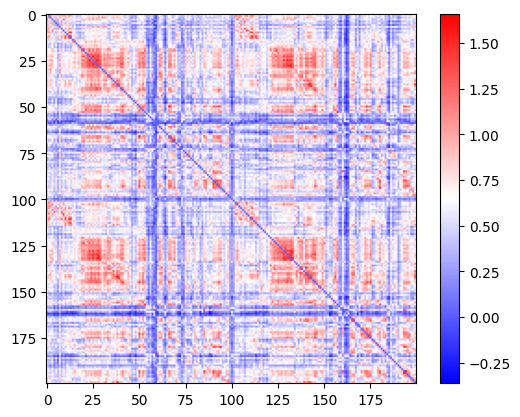

In [21]:
data = np.load("derivatives/fc_matrices/open/fc_matrices/sub-0100_fc.npy")
print(data.shape)

import matplotlib.pyplot as plt
plt.imshow(data, cmap='bwr')
plt.colorbar()